<a href="https://colab.research.google.com/github/nizarmadih/Contextual-QA-Project/blob/main/Notebooks/main.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Projet QA Contextuelle**


## **Partie 1 : Prétraitement et exploration**

### **1. Chargement des datasets :**

#### **Prof Data (goud_articles_split_part_2.csv)**

In [1]:
import pandas as pd
import seaborn as sb
import matplotlib.pyplot as plt
sb.set_theme()

prof_data = pd.read_csv(r"D:/9raya/IID2/S2/Text Mining/Contextual QA/Project/Datasets/goud_articles_split_part_2.csv")
prof_data.head(5)

,title,url,category,content,published_time,modified_time
0,نايضة فجماعة راس العين. لابين بيجي بدات التحقي...,https://www.goud.ma/%d9%86%d8%a7%d9%8a%d8%b6%d...,آش واقع,سامي العلوي -كود كازا //\r\nكشفت مصادر مطلعة ل...,2024-11-04 06:30:01+00:00,2024-11-03T20:58:36+00:00
1,نايضة بين البارصا وتير شتيگن.. وها علاش,https://www.goud.ma/%d9%86%d8%a7%d9%8a%d8%b6%d...,كود سبور,وكالات//\r\nدخل الألماني مارك أندير تير شتيغن،...,2025-07-27 06:00:18+00:00,2025-07-26T22:50:58+00:00
2,البطولة: الوداد ربحو الحسنية ورجعو للصدارة,https://www.goud.ma/%d8%a7%d9%84%d8%a8%d8%b7%d...,كود سبور,گود سبور//\r\nخداو الوداد الرياضي صدارة البطول...,2025-11-05 17:16:31+00:00,NaN
3,تبون ما كانش واضح فكلمتو حول نزاع الصحرا فسلوف...,https://www.goud.ma/%d8%aa%d8%a8%d9%88%d9%86-%...,آش واقع,الوالي الزاز -كود- العيون//\r\n[email protecte...,2025-05-14 13:30:29+00:00,2025-05-14T12:14:23+00:00
4,بسباب اهتمام ترامب بالمعادن النادرة.. مدريد خا...,https://www.goud.ma/%d8%a8%d8%b3%d8%a8%d8%a7%d...,جورنالات بلادي,كود – كازا ///\r\nذكر موقع إخباري بجزر الكناري...,2025-04-29 08:00:36+00:00,2025-04-29T00:59:03+00:00


**Récupérer première paragraphe**

In [2]:
def premier_para(text):
    text1=str(text).split("\n")
    prohibited_text = ['[email\xa0protected]\r', '\r']
    if len(text1)>1 :
        if text1[1] in prohibited_text or text1[1].endswith("//\r") or text1[1].startswith("http"):
            return text1[2]

        else : return text1[1]
    else :
       return text1[0]
   
prof_data["content"] = prof_data["content"].apply(premier_para)

**Suppression des outliers**

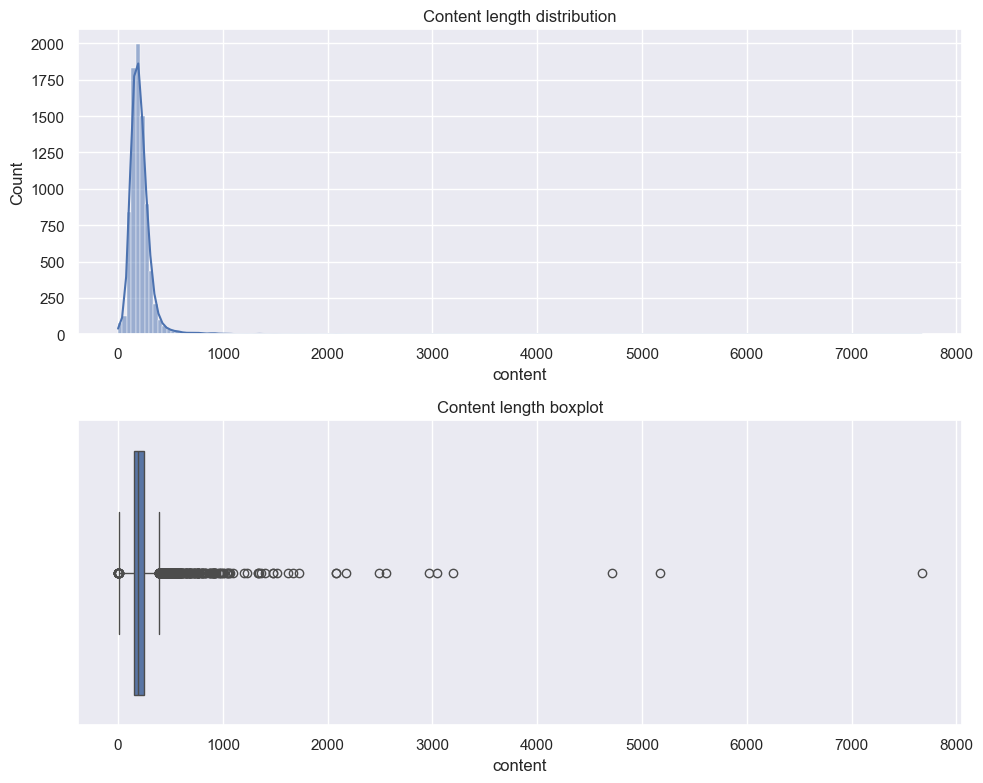

In [3]:
def explore_content(column):
    fig, axes = plt.subplots(2, 1, figsize=(10, 8))
    axes = axes.flatten()

    sb.histplot(column.str.len(), kde=True, ax=axes[0])
    axes[0].set_title("Content length distribution")

    sb.boxplot(x=column.str.len(), ax=axes[1])
    axes[1].set_title("Content length boxplot")
    
    plt.tight_layout()

explore_content(prof_data["content"])

In [4]:
prof_data = prof_data[prof_data["content"].str.len() < prof_data["content"].str.len().quantile(0.99)]
prof_data = prof_data[prof_data["content"].str.len() > prof_data["content"].str.len().quantile(0.01)]
print(prof_data.shape)

(8074, 6)


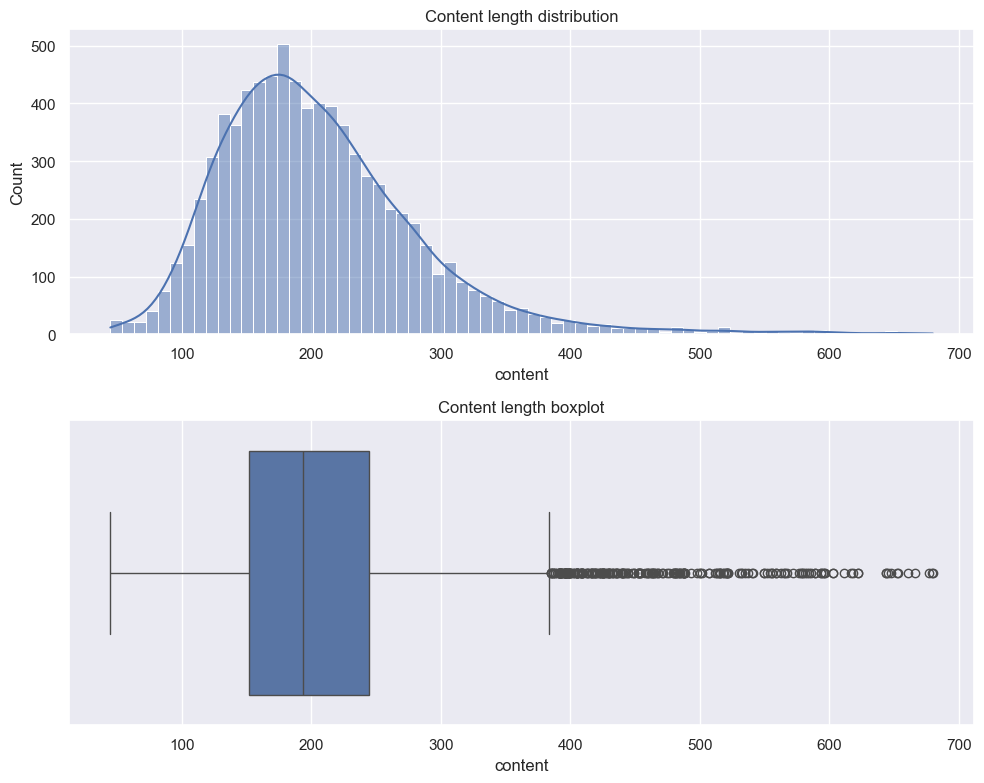

In [5]:
explore_content(prof_data["content"])

#### **Goud.ma dataset (HuggingFace)**

**Charger de la dataset depuis HuggingFace**

In [6]:
import pandas as pd

splits = {'train': 'train.csv', 'validation': 'validation.csv', 'test': 'test.csv'}
goud_df = pd.read_csv("hf://datasets/Goud/Goud-sum/" + splits["train"])

**Récupérer la catégorie de l'article**

In [7]:
import ast

def get_fisrt_category(text):
    # Récupère la première catégorie d'une liste de catégories
    categories = ast.literal_eval(text)
    if len(categories) > 0:
        return categories[0]
    return None

goud_df["categories"] = goud_df["categories"].apply(get_fisrt_category)
goud_df

,article,headline,categories
0,منير العلمي من مراكش: تحول فضاء مقر الغرفة الف...,برلمانيين من حزب الحمامة قلبوها بونيا قبل انتخ...,آش واقع
1,لا حديث في الجسم القضائي الوطني سوى عن الحكم ...,حكم ضد وزارة اعمارة بتعويض قدره 13 مليار لشركة,الرئيسية
2,بانت رواية جديدة فقضية عدم مشاركة إسبانيا فمن...,مغرب آنتيليجانس: المغرب لي عارض مشاركة إسبانيا...,آش واقع
3,مصطفى الشاذلي: عقد حسام البدري، المدير الفني ل...,جلسة خاصة بين مدرب الأهلي ومهاجم الأسود أزارو,الرئيسية
4,كود سبور: كشفت وسائل الإعلام العالمية، صباح ...,اعتقال مهاجم الريال رونالدو في فرنسا… وها علاش...,الرئيسية
...,...,...,...
139283,يتداول الفيسبوكيون صورة لزعيم حزب الاستقلال حم...,ممارسة السياسة عبر الاحفاد. شباط يرد على بنكير...,تبركيك
139284,كشف رئيس الحكومة عبد الاله بنكيران أن الانتخ...,بنكيران: الانتخابات فاكتوبر وخصومي بانضيا وماش...,آش واقع
139285,فتعليقو على إلغاء السفارة دالمانيا لفيزا شينك...,الطبيب حمضي علق على توقيف ألمانيا فيزا شينكَن ...,آش واقع
139286,أكد مصدر من سجن “راس الما” ضواحي مدينة فاس، ل...,عاجل.. الزفزافي واحمجيق وقفو إضرابهم على الماكلة,آش واقع


**Récupérer la première paragraphe**

In [8]:
import re

def split_keep_dot(text):
    # Sépare sur '.', '?' ou '!' tout en gardant la ponctuation
    sentences = re.findall(r'.+?[.!؟]', str(text))
    if len(sentences) > 0:
        return sentences[0]
    return ""

# On garde seulement la première phrase dans "article"
goud_df["article"] = goud_df["article"].apply(split_keep_dot)

# Calcul de la longueur du contexte après découpage
goud_df["context_len"] = goud_df["article"].str.len()

goud_df

,article,headline,categories,context_len
0,منير العلمي من مراكش: تحول فضاء مقر الغرفة الف...,برلمانيين من حزب الحمامة قلبوها بونيا قبل انتخ...,آش واقع,400
1,لا حديث في الجسم القضائي الوطني سوى عن الحكم ...,حكم ضد وزارة اعمارة بتعويض قدره 13 مليار لشركة,الرئيسية,531
2,بانت رواية جديدة فقضية عدم مشاركة إسبانيا فمن...,مغرب آنتيليجانس: المغرب لي عارض مشاركة إسبانيا...,آش واقع,74
3,مصطفى الشاذلي: عقد حسام البدري، المدير الفني ل...,جلسة خاصة بين مدرب الأهلي ومهاجم الأسود أزارو,الرئيسية,189
4,كود سبور: كشفت وسائل الإعلام العالمية، صباح ...,اعتقال مهاجم الريال رونالدو في فرنسا… وها علاش...,الرئيسية,192
...,...,...,...,...
139283,يتداول الفيسبوكيون صورة لزعيم حزب الاستقلال حم...,ممارسة السياسة عبر الاحفاد. شباط يرد على بنكير...,تبركيك,93
139284,كشف رئيس الحكومة عبد الاله بنكيران أن الانتخ...,بنكيران: الانتخابات فاكتوبر وخصومي بانضيا وماش...,آش واقع,104
139285,فتعليقو على إلغاء السفارة دالمانيا لفيزا شينك...,الطبيب حمضي علق على توقيف ألمانيا فيزا شينكَن ...,آش واقع,294
139286,أكد مصدر من سجن “راس الما” ضواحي مدينة فاس، ل...,عاجل.. الزفزافي واحمجيق وقفو إضرابهم على الماكلة,آش واقع,179


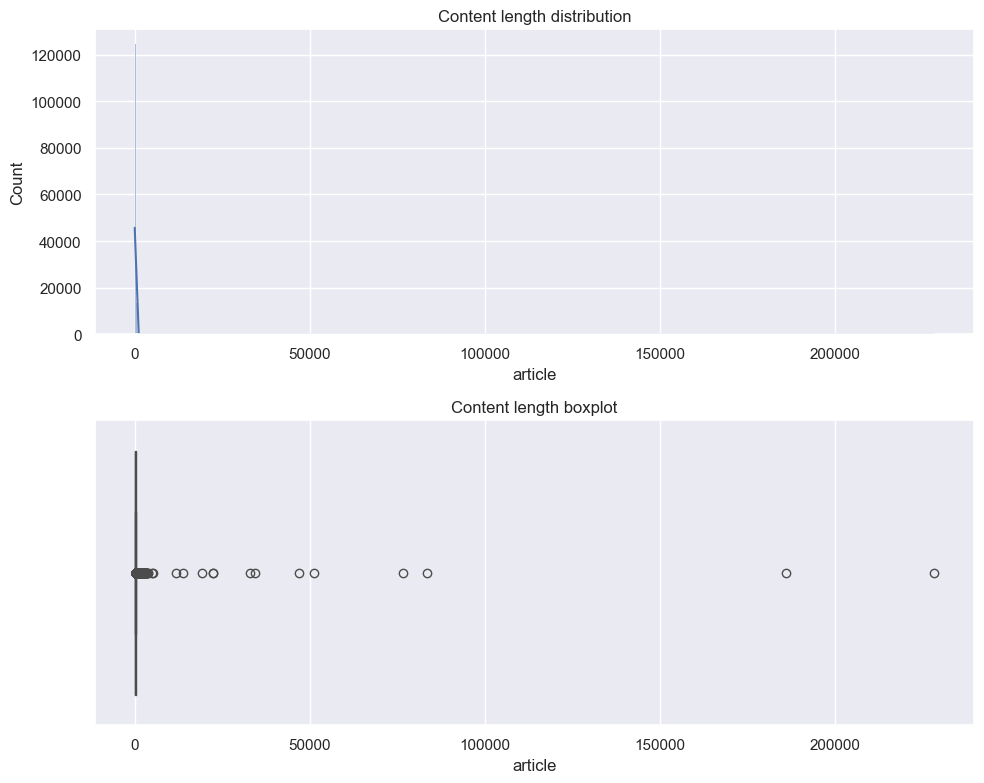

In [9]:
explore_content(goud_df["article"])

**Suppression des outliers**

In [10]:
import matplotlib.pyplot as plt
import seaborn as sb

sb.set_theme()
# On filtre les valeurs extrêmes (10 % inférieur et 10 % supérieur)
goud_df = goud_df[goud_df["context_len"] < goud_df["context_len"].quantile(0.90)]
goud_df = goud_df[goud_df["context_len"] > goud_df["context_len"].quantile(0.10)]
print(goud_df.shape)

(112596, 4)


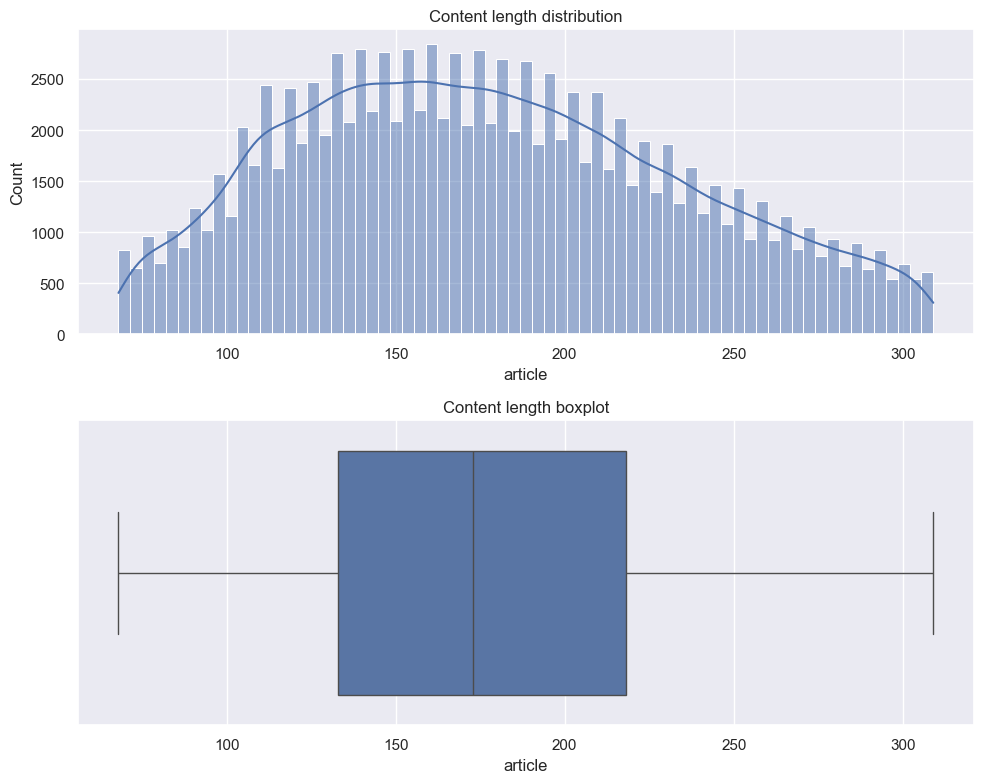

In [11]:
explore_content(goud_df["article"])

In [12]:
# Prépare un DataFrame à exporter avec les colonnes attendues
goud_df.rename(columns={"headline": "title", "categories": "category", "article": "content"}, inplace=True)
goud_df["url"] = None  # pas d'URL disponible
goud_df["published_time"] = None  # date de publication inconnue
goud_df["modified_time"] = None  # date de modification inconnue

#### **Merge All Datasets**

rename colums (required maching column names for merging)

In [13]:
prof_data.rename(columns={"first_paragraph": "context"}, inplace=True)
goud_df.rename(columns={"first_paragraph": "context"}, inplace=True)

In [14]:
prof_data

,title,url,category,content,published_time,modified_time
0,نايضة فجماعة راس العين. لابين بيجي بدات التحقي...,https://www.goud.ma/%d9%86%d8%a7%d9%8a%d8%b6%d...,آش واقع,كشفت مصادر مطلعة لـ”كود”، أن عناصر الفرقة الوط...,2024-11-04 06:30:01+00:00,2024-11-03T20:58:36+00:00
1,نايضة بين البارصا وتير شتيگن.. وها علاش,https://www.goud.ma/%d9%86%d8%a7%d9%8a%d8%b6%d...,كود سبور,دخل الألماني مارك أندير تير شتيغن، حارس مرمى ب...,2025-07-27 06:00:18+00:00,2025-07-26T22:50:58+00:00
2,البطولة: الوداد ربحو الحسنية ورجعو للصدارة,https://www.goud.ma/%d8%a7%d9%84%d8%a8%d8%b7%d...,كود سبور,خداو الوداد الرياضي صدارة البطولة الاحترافية ب...,2025-11-05 17:16:31+00:00,NaN
3,تبون ما كانش واضح فكلمتو حول نزاع الصحرا فسلوف...,https://www.goud.ma/%d8%aa%d8%a8%d9%88%d9%86-%...,آش واقع,استحضر الرئيس الجزائري، عبد المجيد تبون، خلال ...,2025-05-14 13:30:29+00:00,2025-05-14T12:14:23+00:00
4,بسباب اهتمام ترامب بالمعادن النادرة.. مدريد خا...,https://www.goud.ma/%d8%a8%d8%b3%d8%a8%d8%a7%d...,جورنالات بلادي,ذكر موقع إخباري بجزر الكناري، أن مدريد خايفة م...,2025-04-29 08:00:36+00:00,2025-04-29T00:59:03+00:00
...,...,...,...,...,...,...
8236,انطلق السيمانة لي فاتت من برشلونة.. موعد إبحار...,https://www.goud.ma/%d8%a7%d9%86%d8%b7%d9%84%d...,الرئيسية,علنات هيئة أسطول الصمود العالمي، أمس السبت، تأ...,2025-09-07 11:50:02+00:00,2025-09-07T12:00:30+00:00
8237,رئيس القضاء الجنائي فالسلطة القضائية: الجهود ا...,https://www.goud.ma/%d8%b1%d8%a6%d9%8a%d8%b3-%...,آش واقع,أكد حكيم وردي، رئيس قطب القضاء الجنائي بالمجلس...,2025-04-25 18:48:13+00:00,2025-04-26T12:11:44+00:00
8238,واخا ربحو بـ5 ومؤهلين.. الركراكي ما عاطيش الرا...,https://www.goud.ma/%d9%88%d8%a7%d8%ae%d8%a7-%...,كود سبور,غايبدا الناخب الوطني وليد الركراكي والطاقم ديا...,2024-10-13 11:40:46+00:00,2024-10-13T11:51:19+00:00
8239,آخر مكين في الخيانة.. قنعات راجلها يبيع الكلوة...,https://www.goud.ma/%d8%a2%d8%ae%d8%b1-%d9%85%...,تبركيك,كتواجه واحد المرأة هندية من ولاية بنغال الغربي...,2025-02-05 02:00:00+00:00,2025-02-04T23:10:10+00:00


In [15]:
goud_df

,content,title,category,context_len,url,published_time,modified_time
2,بانت رواية جديدة فقضية عدم مشاركة إسبانيا فمن...,مغرب آنتيليجانس: المغرب لي عارض مشاركة إسبانيا...,آش واقع,74,None,None,None
3,مصطفى الشاذلي: عقد حسام البدري، المدير الفني ل...,جلسة خاصة بين مدرب الأهلي ومهاجم الأسود أزارو,الرئيسية,189,None,None,None
4,كود سبور: كشفت وسائل الإعلام العالمية، صباح ...,اعتقال مهاجم الريال رونالدو في فرنسا… وها علاش...,الرئيسية,192,None,None,None
5,عاينت “گود” اليوم انشقاق كبير في القنطرة الترا...,عام باش تبنات.. القنطرة الوحيدة اللي بقات رابط...,آش واقع,247,None,None,None
6,تمكنت عناصر الشرطة لمنطقة عين قادوس بن دباب بف...,حجز طنين من المواد الغدائية فالمحطة الطرقية دي...,الرئيسية,230,None,None,None
...,...,...,...,...,...,...,...
139283,يتداول الفيسبوكيون صورة لزعيم حزب الاستقلال حم...,ممارسة السياسة عبر الاحفاد. شباط يرد على بنكير...,تبركيك,93,None,None,None
139284,كشف رئيس الحكومة عبد الاله بنكيران أن الانتخ...,بنكيران: الانتخابات فاكتوبر وخصومي بانضيا وماش...,آش واقع,104,None,None,None
139285,فتعليقو على إلغاء السفارة دالمانيا لفيزا شينك...,الطبيب حمضي علق على توقيف ألمانيا فيزا شينكَن ...,آش واقع,294,None,None,None
139286,أكد مصدر من سجن “راس الما” ضواحي مدينة فاس، ل...,عاجل.. الزفزافي واحمجيق وقفو إضرابهم على الماكلة,آش واقع,179,None,None,None


merge all datasets into 1 dataframe

In [16]:
total_data = pd.DataFrame()
total_data[["content", "title", "category", "published_time", "modified_time"]] = pd.concat([prof_data[["content", "title", "category", "published_time", "modified_time"]], 
                                                                    goud_df[["content", "title", "category", "published_time", "modified_time"]]], ignore_index=True)

In [17]:
total_data.head(5)

,content,title,category,published_time,modified_time
0,كشفت مصادر مطلعة لـ”كود”، أن عناصر الفرقة الوط...,نايضة فجماعة راس العين. لابين بيجي بدات التحقي...,آش واقع,2024-11-04 06:30:01+00:00,2024-11-03T20:58:36+00:00
1,دخل الألماني مارك أندير تير شتيغن، حارس مرمى ب...,نايضة بين البارصا وتير شتيگن.. وها علاش,كود سبور,2025-07-27 06:00:18+00:00,2025-07-26T22:50:58+00:00
2,خداو الوداد الرياضي صدارة البطولة الاحترافية ب...,البطولة: الوداد ربحو الحسنية ورجعو للصدارة,كود سبور,2025-11-05 17:16:31+00:00,NaN
3,استحضر الرئيس الجزائري، عبد المجيد تبون، خلال ...,تبون ما كانش واضح فكلمتو حول نزاع الصحرا فسلوف...,آش واقع,2025-05-14 13:30:29+00:00,2025-05-14T12:14:23+00:00
4,ذكر موقع إخباري بجزر الكناري، أن مدريد خايفة م...,بسباب اهتمام ترامب بالمعادن النادرة.. مدريد خا...,جورنالات بلادي,2025-04-29 08:00:36+00:00,2025-04-29T00:59:03+00:00


add new column for labelization

In [18]:
total_data.reset_index(drop=True, inplace=True)
total_data.reset_index(inplace=True)
total_data.rename(columns={"index": "id_context"}, inplace=True)

In [19]:
total_data["status"] = "NOT_STARTED"
total_data["verif_status"] = None
total_data["uploaded_at"] = None
total_data["api_account"] = None
total_data["retries"] = 0

In [20]:
total_data.head(3)

,id_context,content,title,category,published_time,modified_time,status,verif_status,uploaded_at,api_account,retries
0,0,كشفت مصادر مطلعة لـ”كود”، أن عناصر الفرقة الوط...,نايضة فجماعة راس العين. لابين بيجي بدات التحقي...,آش واقع,2024-11-04 06:30:01+00:00,2024-11-03T20:58:36+00:00,NOT_STARTED,None,None,None,0
1,1,دخل الألماني مارك أندير تير شتيغن، حارس مرمى ب...,نايضة بين البارصا وتير شتيگن.. وها علاش,كود سبور,2025-07-27 06:00:18+00:00,2025-07-26T22:50:58+00:00,NOT_STARTED,None,None,None,0
2,2,خداو الوداد الرياضي صدارة البطولة الاحترافية ب...,البطولة: الوداد ربحو الحسنية ورجعو للصدارة,كود سبور,2025-11-05 17:16:31+00:00,NaN,NOT_STARTED,None,None,None,0


### **2. Nettoyage et Prétraitement :**

#### **Nettoyage**

**Suppression des emojis**

In [21]:
import pandas as pd
import re
import emoji

def remove_emoji(text):
    text = str(text)
    text_clean = re.sub(r'[^\w\s\u0600-\u06FF\u00C0-\u00FF\u0400-\u04FF\u0900-\u097F.,;:!?\'"()]', '', text, flags=re.UNICODE)
    text_clean = emoji.replace_emoji(text_clean, replace='')

    return text_clean.strip()

total_data["content"] = total_data["content"].apply(remove_emoji)

**Suppression des Urls**

In [22]:
import re
def remove_urls(text):
    if pd.isna(text):
        return ""
    text_str = str(text)
    return re.sub(r'http\S+|www\.\S+','', text_str)
total_data["content"] = total_data["content"].apply(remove_urls)


**Suppression des spam**

In [23]:
def remove_spam(text):
    if pd.isna(text):
        return ""
    text_str = str(text)
    text_str = re.sub(r'\b(?:lol|spam|test)\b', '', text_str, flags=re.IGNORECASE)
    text_str = re.sub(r'[!?.]{2,}', '', text_str)  # Supprime répétitions de ponctuations
    text_str = re.sub(r'\s+', ' ', text_str)       # Remplace espaces multiples par un seul
    return text_str.strip()
total_data["content"] = total_data["content"].apply(remove_spam)

#### **Normalisation**

In [24]:
# Afficher Liste des Caractères uniques
def get_unique_chars(column ,only_arabic=False):
  unique_chars = {}

  for paragraph in column: # chaque ligne
    for char in paragraph: # chaque caractère
      if not only_arabic or (only_arabic and (0x0600 <= ord(char) <= 0x06FF or 0x0750 <= ord(char) <= 0x077F or 0x08A0 <= ord(char) <= 0x08FF)):
        if char in unique_chars: # Ajouter ou incrémenter dans dict
          unique_chars[char] += 1
        else:
          unique_chars[char] = 1

  # trie décroissant avant retourner résultat
  return dict(sorted(unique_chars.items(), key=lambda item: item[1], reverse=True))

# Afficher les mots qui ont ce caractère
def retrieve_words(column, char):
  words_with_char = []
  for paragraph in column:
    words_with_char += [word for word in paragraph.split() if char in word]
  return words_with_char

In [25]:
print("Nombre de lettres ", len(get_unique_chars(total_data["content"])))
print(get_unique_chars(total_data["content"], only_arabic=True))

print("Nombre de lettres (Arabes) ", len(get_unique_chars(total_data["content"], only_arabic=True)))
print(get_unique_chars(total_data["content"], only_arabic=True))

Nombre de lettres  167
{'ا': 2983612, 'ل': 1982848, 'ي': 1426728, 'م': 1146363, 'ر': 843624, 'و': 834238, 'ن': 809181, 'ت': 731999, 'ب': 720680, 'ة': 654243, 'د': 574657, 'ع': 550752, 'س': 434201, 'ف': 405120, 'ق': 352102, 'ٔ': 335350, 'ح': 328593, 'ك': 314558, 'ه': 310489, 'ج': 260666, '،': 241329, 'ص': 193367, 'ش': 186177, 'ط': 178587, 'خ': 147868, 'ز': 124112, 'ض': 110531, 'ى': 109152, 'ٕ': 101697, 'غ': 98558, 'ث': 86524, 'ء': 70855, 'ذ': 59725, 'ظ': 27671, 'أ': 19058, 'ـ': 9101, 'إ': 8451, 'ئ': 6885, 'ٓ': 6741, 'ّ': 4714, 'ً': 4684, 'َ': 4174, 'گ': 3375, 'ُ': 1845, 'ؤ': 1475, '٬': 1363, '؟': 593, 'آ': 590, 'ْ': 332, 'ڤ': 299, 'ِ': 299, 'ٍ': 237, 'ی': 230, 'پ': 225, '؛': 203, '٪': 123, '٫': 86, 'ٌ': 64, 'ڭ': 44, 'ٱ': 36, 'ک': 32, 'ݣ': 30, 'ھ': 27, '١': 15, '٢': 11, '٠': 8, 'ڢ': 4, '٦': 4, 'ٴ': 4, '\u061c': 3, 'ۃ': 2, '٤': 2, 'ٳ': 2, '٧': 2, '٨': 1, 'ڨ': 1, '٩': 1}
Nombre de lettres (Arabes)  77
{'ا': 2983612, 'ل': 1982848, 'ي': 1426728, 'م': 1146363, 'ر': 843624, 'و': 834238, 'ن': 8

**Suppression :** 
  
**- Diacritics (ATTAHWIL)**
  
**- "ـ" Tirets entre lettres arabes (code "0x0640")**

In [ ]:
import re

# Retourne dataset normalisé en arabe
def letter_normalization(paragraph):
    new_paragraph = paragraph

    # Supprimer les Diacritics (ATTAHWIL)
    new_paragraph = re.sub(r"[\u064b-\u0655]", "", new_paragraph)

    # Supprimer les tirets (code "0x0640")
    new_paragraph = re.sub(r"\u0640", "", new_paragraph)

    return new_paragraph

total_data["content"] = total_data["content"].apply(letter_normalization)

### **3. Conversion à Arabizi et Génération des Pairs QA :**

#### **Split Data for Arabizi Conversion**

In [27]:
# Randomly select half of the rows
chosen_part = total_data.sample(frac=0.5, random_state=42)
other_part = total_data.drop(chosen_part.index)
other_part = other_part[~other_part['content'].isin(chosen_part['content'])]

# Split that half into two equal parts
mid_index = len(chosen_part) // 2
df_1 = chosen_part.iloc[:mid_index].reset_index(drop=True)
df_2 = chosen_part.iloc[mid_index:].reset_index(drop=True)
other_part.reset_index(drop=True)

,id_context,content,title,category,published_time,modified_time,status,verif_status,uploaded_at,api_account,retries
0,2,خداو الوداد الرياضي صدارة البطولة الاحترافية ب...,البطولة: الوداد ربحو الحسنية ورجعو للصدارة,كود سبور,2025-11-05 17:16:31+00:00,NaN,NOT_STARTED,None,None,None,0
1,5,اكد رئيس المنظمة الدولية للشرطة الجنائية (الان...,انعقاد الجمعية العامة للإنتربول بمراكش.. رئيس ...,آش واقع,2025-11-21 22:23:44+00:00,NaN,NOT_STARTED,None,None,None,0
2,9,نفذات السلطات المحلية فمدينة سبتة المحتلة، الب...,سبتة دارت أكبر عملية نقل ديال الحراگة نحو إسبا...,جورنالات بلادي,2025-12-05 16:00:17+00:00,2025-12-05T16:45:25+00:00,NOT_STARTED,None,None,None,0
3,10,حصلت كود على شريط فيديو يوثق للهجوم الذي تعرض ...,حصري.. فيديو كيبين كيفاش تعرض البرلماني اللبار...,آش واقع,2024-10-04 14:30:20+00:00,2024-10-04T13:36:35+00:00,NOT_STARTED,None,None,None,0
4,11,تمكنت عناصر الشرطة بمنطقة امن مولاي رشيد بمدين...,بوليس كازا حجزو 9 أطنان ديال الميكة بمنطقة مول...,آش واقع,2025-09-25 18:03:10+00:00,NaN,NOT_STARTED,None,None,None,0
...,...,...,...,...,...,...,...,...,...,...,...
59713,120661,علمت كود، ان المديرية العامة للامن الوطني اقدم...,نايضة تنقيلات أمنية فآسفي بسباب تقرير ما فيه م...,آش واقع,None,None,NOT_STARTED,None,None,None,0
59714,120662,واوضح الوزير في التقدم والاشتراكية بمجلس النوا...,الوردي: المغرب يحتاج إلى 7000 طبيب و9000 ممرض ...,آش واقع,None,None,NOT_STARTED,None,None,None,0
59715,120666,كشف رييس الحكومة عبد الاله بنكيران ان الانتخاب...,بنكيران: الانتخابات فاكتوبر وخصومي بانضيا وماش...,آش واقع,None,None,NOT_STARTED,None,None,None,0
59716,120667,فتعليقو على الغاء السفارة دالمانيا لفيزا شينكن...,الطبيب حمضي علق على توقيف ألمانيا فيزا شينكَن ...,آش واقع,None,None,NOT_STARTED,None,None,None,0


In [28]:
total_data.head(5)

,id_context,content,title,category,published_time,modified_time,status,verif_status,uploaded_at,api_account,retries
0,0,كشفت مصادر مطلعة لكود، ان عناصر الفرقة الوطنية...,نايضة فجماعة راس العين. لابين بيجي بدات التحقي...,آش واقع,2024-11-04 06:30:01+00:00,2024-11-03T20:58:36+00:00,NOT_STARTED,None,None,None,0
1,1,دخل الالماني مارك اندير تير شتيغن، حارس مرمى ب...,نايضة بين البارصا وتير شتيگن.. وها علاش,كود سبور,2025-07-27 06:00:18+00:00,2025-07-26T22:50:58+00:00,NOT_STARTED,None,None,None,0
2,2,خداو الوداد الرياضي صدارة البطولة الاحترافية ب...,البطولة: الوداد ربحو الحسنية ورجعو للصدارة,كود سبور,2025-11-05 17:16:31+00:00,NaN,NOT_STARTED,None,None,None,0
3,3,استحضر الرئيس الجزائري، عبد المجيد تبون، خلال ...,تبون ما كانش واضح فكلمتو حول نزاع الصحرا فسلوف...,آش واقع,2025-05-14 13:30:29+00:00,2025-05-14T12:14:23+00:00,NOT_STARTED,None,None,None,0
4,4,ذكر موقع اخباري بجزر الكناري، ان مدريد خايفة م...,بسباب اهتمام ترامب بالمعادن النادرة.. مدريد خا...,جورنالات بلادي,2025-04-29 08:00:36+00:00,2025-04-29T00:59:03+00:00,NOT_STARTED,None,None,None,0


In [29]:
chosen_part.head(5)

,id_context,content,title,category,published_time,modified_time,status,verif_status,uploaded_at,api_account,retries
114805,114805,تنظر غرفة الجنايات الابتدايية بمحكمة الاستيناف...,خاص. فضيحة ف جامعة مولاي اسماعيل.. اختلاس فلوس...,آش واقع,None,None,NOT_STARTED,None,None,None,0
39057,39057,علمت كود ان مباراة الاياب بين ناديي الزمالك وا...,شوهة..شوفو التيران اللي الوداد غادي تستقبل فيه...,الرئيسية,None,None,NOT_STARTED,None,None,None,0
79929,79929,كشفت ندوة نظمت السبت ضمن فعاليات اكسبو دبي 202...,140 مليون واحد ف العالم كيعانيو من الفقر بسباب...,الرئيسية,None,None,NOT_STARTED,None,None,None,0
45705,45705,تداول نشطاء على نطاق واسع بالموقع الاجتماعي فا...,بالفيديو. مرا فالريف سلخات شيخ بدا كيتحرش بيها,آش واقع,None,None,NOT_STARTED,None,None,None,0
72917,72917,غرفة الجنايات الابتدايية بمحكمة الاستيناف بمرا...,عاجل.. الإعدام لمنفذي جريمة لاكرِيم فمراكش ومو...,آش واقع,None,None,NOT_STARTED,None,None,None,0


In [30]:
other_part.head(5)

,id_context,content,title,category,published_time,modified_time,status,verif_status,uploaded_at,api_account,retries
2,2,خداو الوداد الرياضي صدارة البطولة الاحترافية ب...,البطولة: الوداد ربحو الحسنية ورجعو للصدارة,كود سبور,2025-11-05 17:16:31+00:00,NaN,NOT_STARTED,None,None,None,0
5,5,اكد رئيس المنظمة الدولية للشرطة الجنائية (الان...,انعقاد الجمعية العامة للإنتربول بمراكش.. رئيس ...,آش واقع,2025-11-21 22:23:44+00:00,NaN,NOT_STARTED,None,None,None,0
9,9,نفذات السلطات المحلية فمدينة سبتة المحتلة، الب...,سبتة دارت أكبر عملية نقل ديال الحراگة نحو إسبا...,جورنالات بلادي,2025-12-05 16:00:17+00:00,2025-12-05T16:45:25+00:00,NOT_STARTED,None,None,None,0
10,10,حصلت كود على شريط فيديو يوثق للهجوم الذي تعرض ...,حصري.. فيديو كيبين كيفاش تعرض البرلماني اللبار...,آش واقع,2024-10-04 14:30:20+00:00,2024-10-04T13:36:35+00:00,NOT_STARTED,None,None,None,0
11,11,تمكنت عناصر الشرطة بمنطقة امن مولاي رشيد بمدين...,بوليس كازا حجزو 9 أطنان ديال الميكة بمنطقة مول...,آش واقع,2025-09-25 18:03:10+00:00,NaN,NOT_STARTED,None,None,None,0


In [31]:
df_1.head(5)

,id_context,content,title,category,published_time,modified_time,status,verif_status,uploaded_at,api_account,retries
0,114805,تنظر غرفة الجنايات الابتدايية بمحكمة الاستيناف...,خاص. فضيحة ف جامعة مولاي اسماعيل.. اختلاس فلوس...,آش واقع,None,None,NOT_STARTED,None,None,None,0
1,39057,علمت كود ان مباراة الاياب بين ناديي الزمالك وا...,شوهة..شوفو التيران اللي الوداد غادي تستقبل فيه...,الرئيسية,None,None,NOT_STARTED,None,None,None,0
2,79929,كشفت ندوة نظمت السبت ضمن فعاليات اكسبو دبي 202...,140 مليون واحد ف العالم كيعانيو من الفقر بسباب...,الرئيسية,None,None,NOT_STARTED,None,None,None,0
3,45705,تداول نشطاء على نطاق واسع بالموقع الاجتماعي فا...,بالفيديو. مرا فالريف سلخات شيخ بدا كيتحرش بيها,آش واقع,None,None,NOT_STARTED,None,None,None,0
4,72917,غرفة الجنايات الابتدايية بمحكمة الاستيناف بمرا...,عاجل.. الإعدام لمنفذي جريمة لاكرِيم فمراكش ومو...,آش واقع,None,None,NOT_STARTED,None,None,None,0


In [32]:
df_2.head(5)

,id_context,content,title,category,published_time,modified_time,status,verif_status,uploaded_at,api_account,retries
0,40470,نفذ قايد طايرة صغيرة مخصصة لممارسة رياضة القفز...,بالفيديو. طيارة كانت غادير كارثة ونزلات فوسط ا...,الرئيسية,None,None,NOT_STARTED,None,None,None,0
1,61229,كشفت مصادر محلية بمدينة شيشاوة ل كود ان شبهة ت...,مشروع “النفايات الطبية” بالملايير كيهدد صحة سا...,آش واقع,None,None,NOT_STARTED,None,None,None,0
2,28799,استنفر بضعة اشخاص محسوبون على حركة عشرين فبراي...,فلول 20 فبراير مع المقاطعة: ما هي انتخابات: اس...,آش واقع,None,None,NOT_STARTED,None,None,None,0
3,115420,تمكن عابد بادل، وكيل لايحة حزب التجمع الوطني ل...,جهة كازا سطات.. لائحة التجمعي عابد بادل خدات ج...,آش واقع,None,None,NOT_STARTED,None,None,None,0
4,108698,صباح اليوم الاثنين 26 ابريل 2021، اكتشف احد ال...,البوليس كايحقق بعدما لقاو جمجمة بشرية قريب من ...,آش واقع,None,None,NOT_STARTED,None,None,None,0


#### **Conversion to Arabizi + Generating Question/Answer Pairs...**

#### **Merge Labelized Datasets**

**Load Part 1**

In [2]:
import pandas as pd
import seaborn as sb
import matplotlib.pyplot as plt

labelized_1_df = pd.read_csv("labelized_1.csv")
manual_labelized_1_df = pd.read_csv("manually_labelized_1.csv")

In [3]:
labelized_1_df

,fichier_source,context_id,worker_id,context,question,answer,type,generated_at
0,unlabelized_dataset_part1.csv,7,4,علمت “كود”، من مصادر مقربة من رئيس الحكومة ال...,شكون هو الشخص اللي كتهضر عليه المصادر المقربة؟,عبد الإله بنكيران,Who,2026-03-23T16:09:34.116824+00:00
1,unlabelized_dataset_part1.csv,7,4,علمت “كود”، من مصادر مقربة من رئيس الحكومة ال...,شكون هي السيدة اللي غادي تحضر للعشاء؟,نبيلة بنكيران,Who,2026-03-23T16:09:34.116824+00:00
2,unlabelized_dataset_part1.csv,7,4,علمت “كود”، من مصادر مقربة من رئيس الحكومة ال...,فين جا القصر اللي تنظم فيه العشاء؟,بمدينة طنجة,Where,2026-03-23T16:09:34.116824+00:00
3,unlabelized_dataset_part1.csv,7,4,علمت “كود”، من مصادر مقربة من رئيس الحكومة ال...,شنو هي المناسبة اللي تدار على قبلها هاد العشاء؟,عيد العرش,What,2026-03-23T16:09:34.116824+00:00
4,unlabelized_dataset_part1.csv,7,4,علمت “كود”، من مصادر مقربة من رئيس الحكومة ال...,شحال هي الذكرى ديال هاد المناسبة؟,الـ19,How Many,2026-03-23T16:09:34.116824+00:00
...,...,...,...,...,...,...,...,...
33923,unlabelized_dataset_part1.csv,9795,1,كود جمال مايس- علمت “كود” أن مجموعة من المواط...,شحال من سيدة تم القبض عليها؟,سيدتان,How Many,2026-04-05T12:41:35.524748+00:00
33924,unlabelized_dataset_part1.csv,9797,1,beqalam: sa3id sa3di 2innahu 2idhan ra2is dawl...,Chkoune houwa ra2is dawla iftiradi?,sa3id sa3di,Who,2026-04-05T12:41:42.426020+00:00
33925,unlabelized_dataset_part1.csv,9797,1,beqalam: sa3id sa3di 2innahu 2idhan ra2is dawl...,Lfin mcha had ra2is?,sotchi,Where,2026-04-05T12:41:42.426020+00:00
33926,unlabelized_dataset_part1.csv,9797,1,beqalam: sa3id sa3di 2innahu 2idhan ra2is dawl...,Chkoune li mcha l3endo bach ytm2no 3la elwadh3...,erra2is errousi,Who,2026-04-05T12:41:42.426020+00:00


In [4]:
manual_labelized_1_df

,fichier_source,context_id,worker_id,context,question,answer,type,generated_at
0,unlabelized_dataset_part1.csv,100000,0,اصدر وكيل الملك لدى المحكمة الابتدائية بخنيفر...,شكون لي أصدر التعليمات؟,وكيل الملك,Who,NaN
1,unlabelized_dataset_part1.csv,100000,0,اصدر وكيل الملك لدى المحكمة الابتدائية بخنيفر...,\tمنين صدرات التعليمات؟,لمحكمة الابتدائية بخنيفرة,Where,NaN
2,unlabelized_dataset_part1.csv,100000,0,اصدر وكيل الملك لدى المحكمة الابتدائية بخنيفر...,شكون لي تعطاتو التعليمات؟,المركز القضائي للدرك الملكي,Who,NaN
3,unlabelized_dataset_part1.csv,100000,0,اصدر وكيل الملك لدى المحكمة الابتدائية بخنيفر...,شنو هي الواقعة لي كيتحققو فيها؟,تدنيس المقبرة القديمة لمولاي بوعزة عبر نبش قبر...,What,NaN
4,unlabelized_dataset_part1.csv,100000,0,اصدر وكيل الملك لدى المحكمة الابتدائية بخنيفر...,شمن حاجة دارو فالمقبرة؟,نبش قبر و العبث برفاته,Which,NaN
...,...,...,...,...,...,...,...,...
1121,unlabelized_dataset_part1.csv,100396,0,بدى الزعيم السابق لجزر المالديف محمد نشيد مستم...,فين بدى الزعيم السابق لجزر المالديف محمد نشيد ...,في مهرجان في ويلز ببريطانيا,Where,NaN
1122,unlabelized_dataset_part1.csv,100397,0,أعلنت وزارة الصحة الجزائرية، مساء اليوم الأ...,\tشمن وزارة أعلنت؟,\tوزارة الصحة الجزائرية,Which,NaN
1123,unlabelized_dataset_part1.csv,100397,0,أعلنت وزارة الصحة الجزائرية، مساء اليوم الأ...,شحال من حالة إصابة جديدة؟,بـ104 حالة جديدة,How many,NaN
1124,unlabelized_dataset_part1.csv,100397,0,أعلنت وزارة الصحة الجزائرية، مساء اليوم الأ...,\tكم أصبح العدد الإجمالي؟,1572,How many,NaN


**Load Part 2**

In [6]:
labelized_2_df = pd.read_csv("labelized_2.csv")
manual_labelized_2_df = pd.read_csv("manually_labelized_2.csv")

In [8]:
labelized_2_df

,fichier_source,context_id,worker_id,context,question,answer,type,generated_at
0,Nizar Test/Labelization/unlabelized_dataset_pa...,2,2,قالت مصادر مطلعة ل”كود”، أن فاطمة الزهراء الم...,شكون هي الشخصية اللي كتدير هاد المشاورات؟,فاطمة الزهراء المنصوري,Who,2026-03-25T15:29:30.286697+00:00
1,Nizar Test/Labelization/unlabelized_dataset_pa...,2,2,قالت مصادر مطلعة ل”كود”، أن فاطمة الزهراء الم...,فأشمن شهر غادي ينعقد الموتمر الرابع؟,شتنبر,When,2026-03-25T15:29:30.286715+00:00
2,Nizar Test/Labelization/unlabelized_dataset_pa...,2,2,قالت مصادر مطلعة ل”كود”، أن فاطمة الزهراء الم...,شنو هو الحزب اللي كيتكلم عليه النص؟,البام,What,2026-03-25T15:29:30.286719+00:00
3,Nizar Test/Labelization/unlabelized_dataset_pa...,3,1,"ba3d el5abar elli sab9 wa2n nacharnah fi ""koud...",Chkoun li sifet lajna lmadinat el3ayoun?,el3arabi bnsheekh,Who,2026-03-25T15:30:20.630919+00:00
4,Nizar Test/Labelization/unlabelized_dataset_pa...,3,1,"ba3d el5abar elli sab9 wa2n nacharnah fi ""koud...",Fina mdina ghadi tkhdem had el-lajna?,el3ayoun,Where,2026-03-25T15:30:20.630931+00:00
...,...,...,...,...,...,...,...,...
58843,Nizar Test/Labelization/unlabelized_dataset_pa...,17620,2,أعلن المكتب الإقليمي للاتحاد الوطني للشغل بالم...,شنو هو القطاع اللي كيعيش أوضاع مزرية حسب البيان؟,قطاع الزليج,What,2026-04-04T23:10:36.491871+00:00
58844,Nizar Test/Labelization/unlabelized_dataset_pa...,17622,3,في خطوة لافتة خلال عطلته الصيفية، حضر النجم ال...,شكون هو اللاعب اللي حضر الحفل؟,أردا غولر,Who,2026-04-04T23:10:40.360596+00:00
58845,Nizar Test/Labelization/unlabelized_dataset_pa...,17622,3,في خطوة لافتة خلال عطلته الصيفية، حضر النجم ال...,فين تنظم هاد الحفل؟,مدينة أنطاليا,Where,2026-04-04T23:10:40.360606+00:00
58846,Nizar Test/Labelization/unlabelized_dataset_pa...,17622,3,في خطوة لافتة خلال عطلته الصيفية، حضر النجم ال...,شنو سميت الجولة العالمية ديال الفنانة؟,استيقظ طوال الليل,What,2026-04-04T23:10:40.360609+00:00


In [10]:
manual_labelized_2_df

,Unnamed: 0.1,Unnamed: 0,fichier_source,context_id,worker_id,context,question,answer,type,generated_at
0,292,292,unlabelized_dataset_part1.csv,95,0,حشومة وعيب وعار ان قللة قليلة من الديموقراطيين...,فين وقع هاد المسلسل ديال قتل التجربة الديموقرا...,فالمغرب,Where,NaN
1,428,428,unlabelized_dataset_part1.csv,136,0,كنت أحب أن تكون هذه الشهادة على شكل مقالة كر...,شكون الشخص اللي كان خاصو يقرا هاد الشهادة فصحافة؟,عبد اللطيف بنيحيى,Who,NaN
2,561,561,unlabelized_dataset_part1.csv,177,0,المغني المغربي زهير البهاوي كان ضيف فواحد البر...,شكون هو الفنان اللي كان ضيف فواحد البرنماج الت...,زهير البهاوي,Who,NaN
3,920,920,unlabelized_dataset_part1.csv,278,0,لم يخرج حزب التجمع الوطني للاحرار بقرار واضح ب...,شكون هو الحزب اللي مازال ما خرجش بقرار واضح بخ...,حزب التجمع الوطني للاحرار,Who,NaN
4,1110,1110,unlabelized_dataset_part1.csv,329,0,كولشي مقلوب فهاد الحكومة، حتا شفنا أعضاء دواي...,شكون اللي ولاو كيعطيو تصريحات بحال يلا هما ناط...,أعضاء دوايين وزارية ومستشار رئيس الحكومة,Who,NaN
...,...,...,...,...,...,...,...,...,...,...
465,92941,57887,Nizar Test/Labelization/unlabelized_dataset_pa...,17112,0,يتأكد مع توالي الأيام والأحداث أن مغرب الا...,شنو هو الوصف اللي تعطى للمغرب فهاد النص؟,مغرب الألفية الثالثة,What,NaN
466,92976,57922,Nizar Test/Labelization/unlabelized_dataset_pa...,17123,0,Le mois d’aout au Maroc a ceci de particulier ...,Achmen chhar f l3am li 3ndou had lkhousousiya ...,aout,When,NaN
467,93182,58128,Nizar Test/Labelization/unlabelized_dataset_pa...,17180,0,الألبوم يمزج بين إيقاعات كثيرة منها الإيقاع...,شنو هما النوع د الإيقاعات اللي كاينين ف هاد ال...,الإيقاعات الموسيقية المغربية,What,NaN
468,93193,58139,Nizar Test/Labelization/unlabelized_dataset_pa...,17184,0,معمر وقعات فموقع “كود ” أن شي مسؤول ولا وزير ل...,شنو هو الموقع اللي كيهضر عليه النص؟,كود,What,NaN


**Merging Parts**

In [11]:
labelized_df = pd.concat([labelized_1_df, manual_labelized_1_df, labelized_2_df, manual_labelized_2_df])

In [13]:
labelized_df

,fichier_source,context_id,worker_id,context,question,answer,type,generated_at,Unnamed: 0.1,Unnamed: 0
0,unlabelized_dataset_part1.csv,7,4,علمت “كود”، من مصادر مقربة من رئيس الحكومة ال...,شكون هو الشخص اللي كتهضر عليه المصادر المقربة؟,عبد الإله بنكيران,Who,2026-03-23T16:09:34.116824+00:00,NaN,NaN
1,unlabelized_dataset_part1.csv,7,4,علمت “كود”، من مصادر مقربة من رئيس الحكومة ال...,شكون هي السيدة اللي غادي تحضر للعشاء؟,نبيلة بنكيران,Who,2026-03-23T16:09:34.116824+00:00,NaN,NaN
2,unlabelized_dataset_part1.csv,7,4,علمت “كود”، من مصادر مقربة من رئيس الحكومة ال...,فين جا القصر اللي تنظم فيه العشاء؟,بمدينة طنجة,Where,2026-03-23T16:09:34.116824+00:00,NaN,NaN
3,unlabelized_dataset_part1.csv,7,4,علمت “كود”، من مصادر مقربة من رئيس الحكومة ال...,شنو هي المناسبة اللي تدار على قبلها هاد العشاء؟,عيد العرش,What,2026-03-23T16:09:34.116824+00:00,NaN,NaN
4,unlabelized_dataset_part1.csv,7,4,علمت “كود”، من مصادر مقربة من رئيس الحكومة ال...,شحال هي الذكرى ديال هاد المناسبة؟,الـ19,How Many,2026-03-23T16:09:34.116824+00:00,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...
465,Nizar Test/Labelization/unlabelized_dataset_pa...,17112,0,يتأكد مع توالي الأيام والأحداث أن مغرب الا...,شنو هو الوصف اللي تعطى للمغرب فهاد النص؟,مغرب الألفية الثالثة,What,NaN,92941.0,57887.0
466,Nizar Test/Labelization/unlabelized_dataset_pa...,17123,0,Le mois d’aout au Maroc a ceci de particulier ...,Achmen chhar f l3am li 3ndou had lkhousousiya ...,aout,When,NaN,92976.0,57922.0
467,Nizar Test/Labelization/unlabelized_dataset_pa...,17180,0,الألبوم يمزج بين إيقاعات كثيرة منها الإيقاع...,شنو هما النوع د الإيقاعات اللي كاينين ف هاد ال...,الإيقاعات الموسيقية المغربية,What,NaN,93182.0,58128.0
468,Nizar Test/Labelization/unlabelized_dataset_pa...,17184,0,معمر وقعات فموقع “كود ” أن شي مسؤول ولا وزير ل...,شنو هو الموقع اللي كيهضر عليه النص؟,كود,What,NaN,93193.0,58139.0


In [ ]:
labelized_df.shape

**Save Labelized Dataset**

In [40]:
labelized_df.to_csv("labelized_dataset.csv")

### **4. Analyse exploratoire :**

#### **Analyse des Contextes**

In [ ]:
context_df = labelized_df.drop_duplicates(subset=['context_id', "context"], keep='first')
context_df = context_df[["context"]]
context_df.rename(columns={"context": "first_paragraph"}, inplace=True)
context_df

,first_paragraph
0,علمت “كود”، من مصادر مقربة من رئيس الحكومة ال...
5,temeknet fer9et echortet el9odaiya ettabi3a le...
9,وأبرزت الصحف التركية أن مدة العقد قد تصل إل...
12,"9alat nazha elwafi, elwazira elmontadiba elmok..."
15,أحمد الطيب: علمت “كود” من مصادر خاصة، أن الم...
...,...
58830,قال وزير الفلاحة والصيد البحري والتنمية القروي...
58834,"3ilmet “koud” men masdar 7izbi, 2n el2amin el3..."
58837,أعلنت هيئة الإذاعة البريطانية عن وفاة الروا...
58842,أعلن المكتب الإقليمي للاتحاد الوطني للشغل بالم...


In [53]:
#Nombre de contextes
context_df["first_paragraph"].shape[0]

26864

In [54]:
#Longueur des contextes
context_df["nombre_mots"]=context_df["first_paragraph"].apply(lambda x: len(x.split()))
print("Longueur en mots :")
print("Min :", context_df["nombre_mots"].min())
print("Max :", context_df["nombre_mots"].max())
print("Moyenne :", context_df["nombre_mots"].mean())


Longueur en mots :
Min : 1
Max : 107
Moyenne : 29.137581893984514


In [55]:
context_df["nombre_Caracteres"]=context_df["first_paragraph"].apply(lambda x: len(x))
print("Longueur en caracteres :")
print("Min :", context_df["nombre_Caracteres"].min())
print("Max :", context_df["nombre_Caracteres"].max())
print("Moyenne :", context_df["nombre_Caracteres"].mean())


Longueur en caracteres :
Min : 48
Max : 661
Moyenne : 189.36725729600954


In [56]:
texte_total=' '.join(context_df["first_paragraph"].astype(str))
mots = re.findall(r'\b\w+\b', texte_total.lower())

In [57]:
from collections import Counter
fr_mots=Counter(mots)
print(fr_mots.most_common(10))

[('ا', 37151), ('من', 16127), ('في', 15357), ('الا', 13807), ('على', 8665), ('ن', 6392), ('fi', 4688), ('كود', 3712), ('اليوم', 3494), ('min', 3437)]


In [58]:
!pip install arabic-reshaper python-bidi

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 25.1.1 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [59]:
# la correction d affichage
import arabic_reshaper
from bidi.algorithm import get_display

def fix_arabic(text):
    reshaped_text = arabic_reshaper.reshape(text)
    return get_display(reshaped_text)

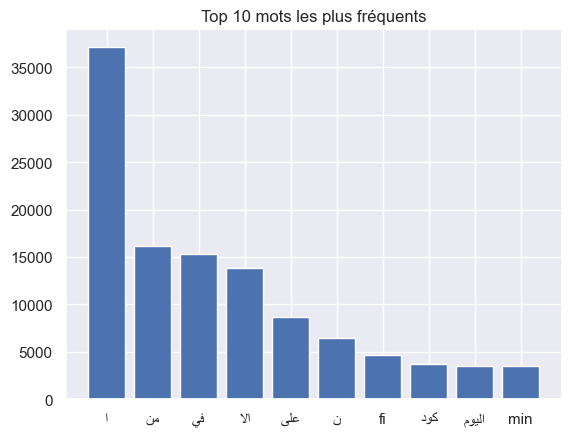

In [60]:
top10 = fr_mots.most_common(10)
mots_top = [x[0] for x in top10]
freq_top = [x[1] for x in top10]
mots_arabe=[fix_arabic(mot) for mot in mots_top]
plt.figure()
plt.bar(mots_arabe, freq_top)
plt.title("Top 10 mots les plus fréquents")
plt.show()

In [61]:
import pandas as pd
import re
import nltk
nltk.download('words')
from nltk.corpus import words

# Dictionnaire anglais complet
english_words = set(words.words())

[nltk_data] Downloading package words to
[nltk_data]     C:\Users\exe\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\words.zip.


In [62]:
!pip install pyspellchecker


Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/7.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/7.2 MB ? eta -:--:--
   ------- -------------------------------- 1.3/7.2 MB 5.8 MB/s eta 0:00:02
   ------------------ --------------------- 3.4/7.2 MB 8.2 MB/s eta 0:00:01
   ------------------------------ --------- 5.5/7.2 MB 8.7 MB/s eta 0:00:01
   ---------------------------------------  7.1/7.2 MB 8.7 MB/s eta 0:00:01
   ---------------------------------------- 7.2/7.2 MB 8.5 MB/s eta 0:00:00



[notice] A new release of pip is available: 25.1.1 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [63]:
from spellchecker import SpellChecker
spell_fr = SpellChecker(language='fr')

In [64]:
import re

def is_arabic(text, threshold=0.7):
    text = str(text)
    arabic_chars = re.findall(r'[\u0600-\u06FF]', text)
    total_chars = len(re.findall(r'\w', text))  # tous les caractères alphanumériques
    if total_chars == 0:
        return False
    return len(arabic_chars)/total_chars >= threshold

In [65]:
def is_english(text):
    return str(text).lower() in english_words

def is_french(text):
    return str(text).lower() in spell_fr


In [66]:
def detect_type(text):
    text = str(text).strip()
    if is_arabic(text):
        return "arabic"
    elif is_french(text):
        return "french"
    elif is_english(text):
        return "english"
    else:
        return "arabizi"

In [67]:
def count_arabic_letters(text):
    return len(re.findall(r'[\u0600-\u06FF]', str(text)))

def count_latin_letters(text):
    return len(re.findall(r'[a-zA-Z]', str(text)))

In [68]:
context_df["type"] = context_df["first_paragraph"].apply(detect_type)

In [69]:
context_df.columns

Index(['first_paragraph', 'nombre_mots', 'nombre_Caracteres', 'type'], dtype='str')

In [70]:
arabizi_df = context_df[context_df["type"] == "arabizi"].copy()
arabizi_df["arabic_letters"] = arabizi_df["first_paragraph"].apply(count_arabic_letters)
arabizi_df["latin_letters"] = arabizi_df["first_paragraph"].apply(count_latin_letters)

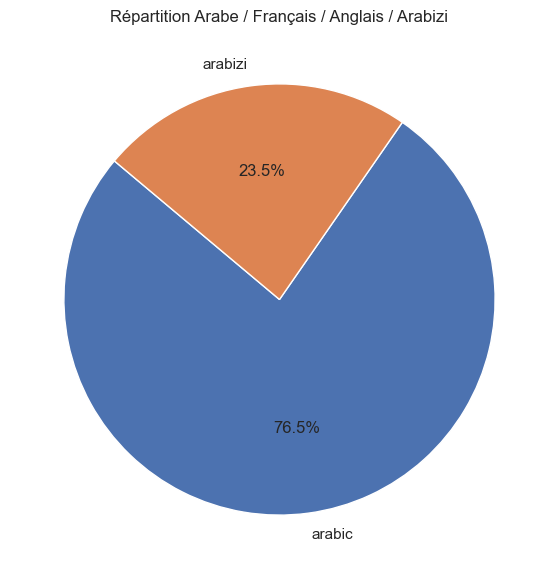

In [71]:
counts = context_df["type"].value_counts()
plt.figure(figsize=(7,7))
plt.pie(counts, labels=counts.index, autopct='%1.1f%%', startangle=140)
plt.title("Répartition Arabe / Français / Anglais / Arabizi")
plt.show()

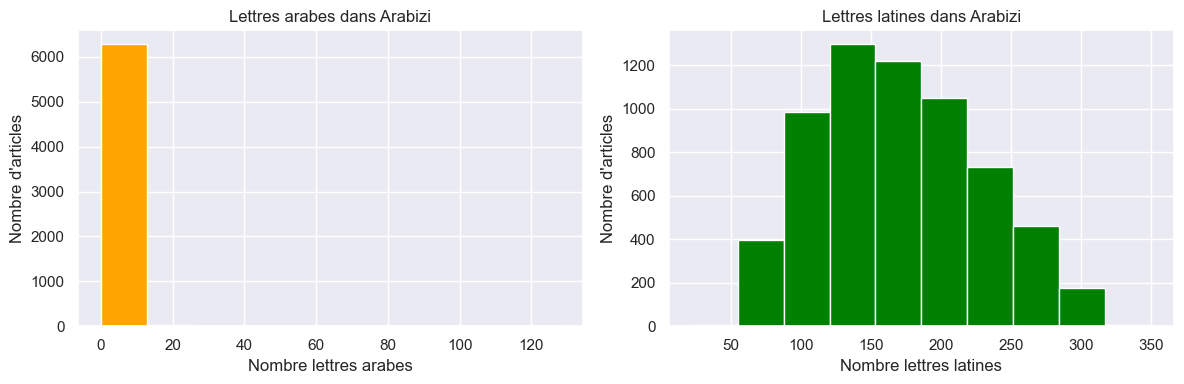

In [72]:
plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
plt.hist(arabizi_df["arabic_letters"], bins=10, color='orange')
plt.title("Lettres arabes dans Arabizi")
plt.xlabel("Nombre lettres arabes")
plt.ylabel("Nombre d'articles")

plt.subplot(1,2,2)
plt.hist(arabizi_df["latin_letters"], bins=10, color='green')
plt.title("Lettres latines dans Arabizi")
plt.xlabel("Nombre lettres latines")
plt.ylabel("Nombre d'articles")
plt.tight_layout()
plt.show()


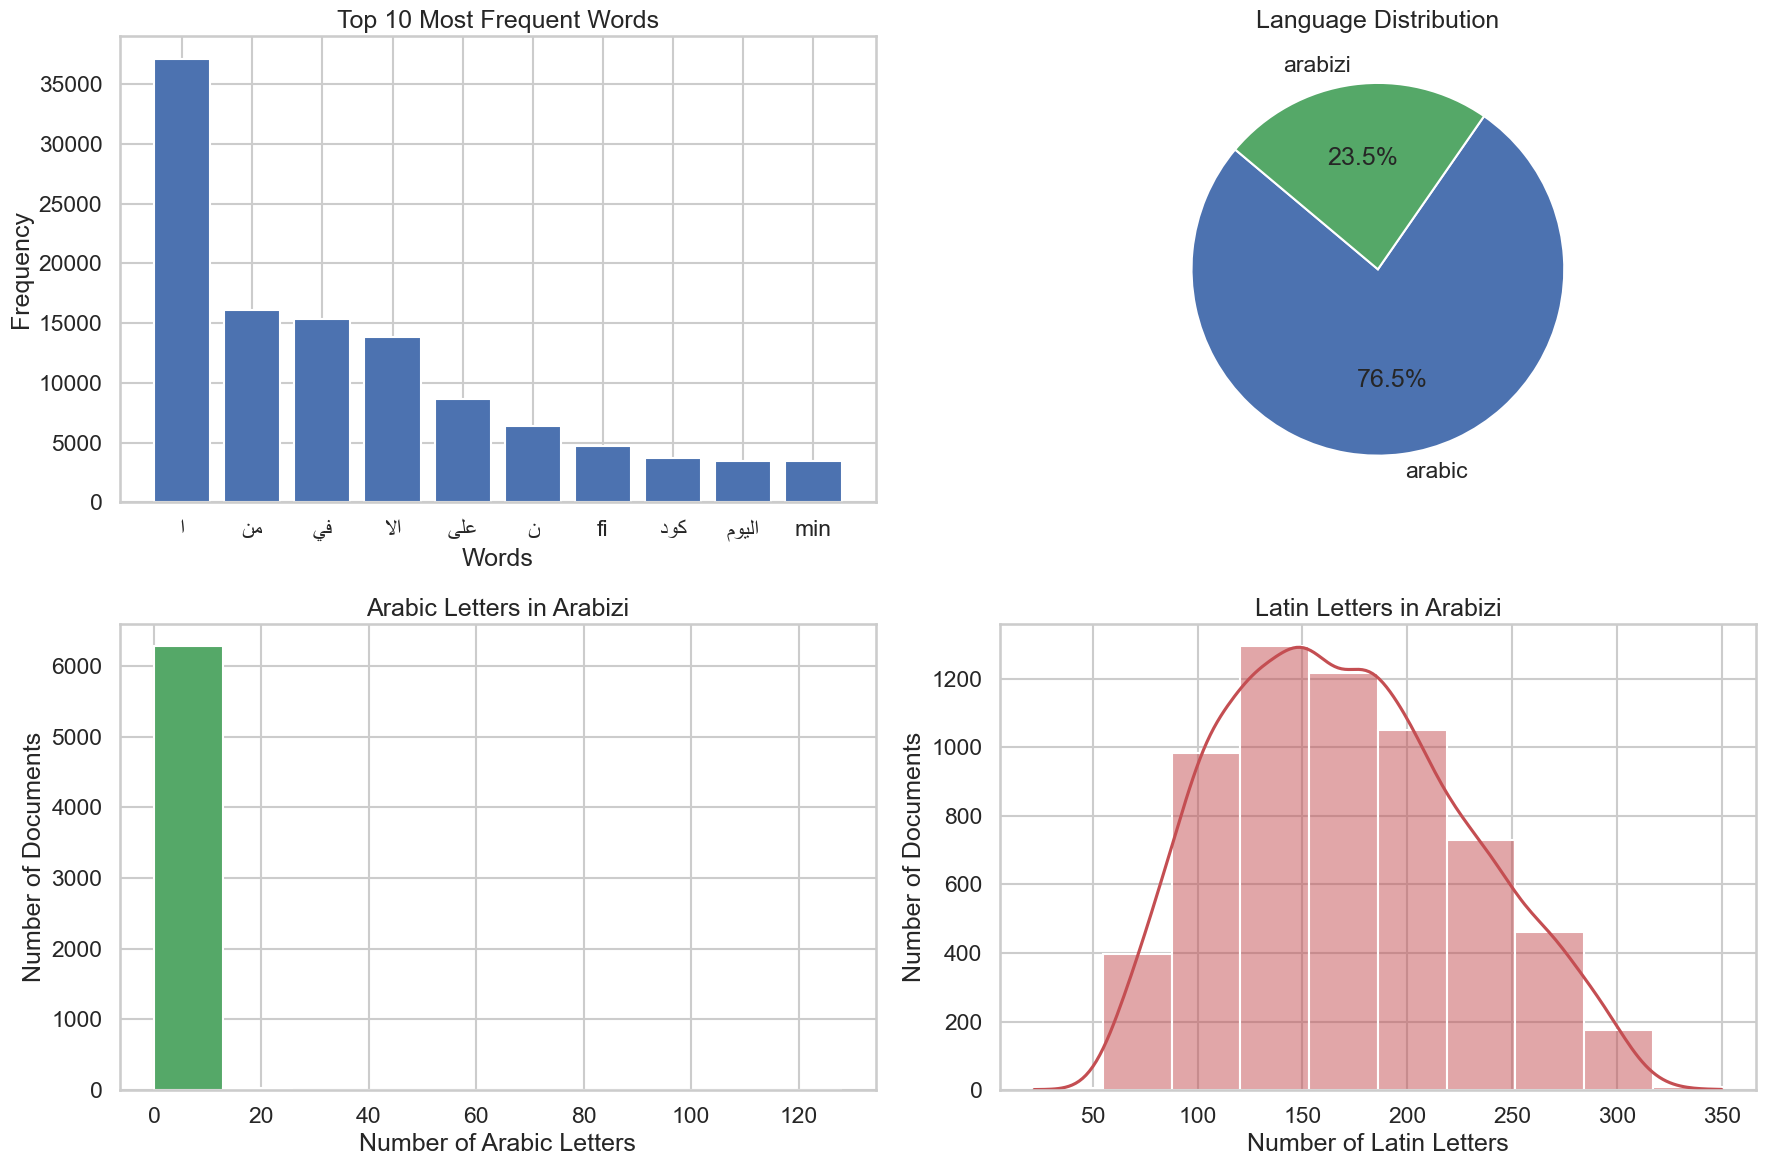

In [176]:
import seaborn as sns

import matplotlib.pyplot as plt

# Create figure with 2 rows, 2 columns
fig, axes = plt.subplots(2, 2, figsize=(18, 12))
axes = axes.flatten()

# -------------------------
# 1. Top 10 frequent words
# -------------------------
top10 = fr_mots.most_common(10)
mots_top = [x[0] for x in top10]
freq_top = [x[1] for x in top10]
mots_arabe = [fix_arabic(mot) for mot in mots_top]

axes[0].bar(mots_arabe, freq_top, color="#4C72B0")  # muted blue
axes[0].set_title("Top 10 Most Frequent Words")
axes[0].set_xlabel("Words")
axes[0].set_ylabel("Frequency")
axes[0].tick_params(axis='x')

# -------------------------
# 2. Type distribution (pie)
# -------------------------
counts = context_df["type"].value_counts()

axes[1].pie(
    counts,
    labels=counts.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=["#4C72B0", "#55A868", "#C44E52", "#8172B3"][:len(counts)]
)

axes[1].set_title("Language Distribution")

# -------------------------
# 3. Arabic letters in Arabizi
# -------------------------
axes[2].hist(
    arabizi_df["arabic_letters"],
    bins=10,
    color="#55A868"  # muted green
)

axes[2].set_title("Arabic Letters in Arabizi")
axes[2].set_xlabel("Number of Arabic Letters")
axes[2].set_ylabel("Number of Documents")

# -------------------------
# 4. Latin letters in Arabizi
# -------------------------
# ... existing code ...

# ------------------------- 
# 4. Latin letters in Arabizi
# -------------------------
sns.histplot(
    data=arabizi_df,
    x="latin_letters",
    bins=10,
    color="#C44E52",  # muted red
    kde=True,
    ax=axes[3]
)

axes[3].set_title("Latin Letters in Arabizi")
axes[3].set_xlabel("Number of Latin Letters")
axes[3].set_ylabel("Number of Documents")

plt.tight_layout()
plt.show()

#### **Analyse du code-switching**

**Traitement :**

In [74]:
from enum import unique
import copy
import regex

# pattern pour juste latin caractères
reg_pattern = regex.compile(r'\p{Script=Latin}')

# Analyse code-switching pour une paragraph
def extract_latin_segments_with_char_pos(paragraph):
    if not isinstance(paragraph, str):
        return []

    segments = []
    temp_words = []
    start_idx = None
    char_idx = 0  # running character index

    words = paragraph.split()

    for word in words:
        # check if word contains Latin letters
        if reg_pattern.search(word):
            if temp_words == []:
                start_idx = char_idx  # record starting char index
            temp_words.append(word)
        else:
            if temp_words:
                segments.append((" ".join(temp_words), start_idx))
                temp_words = []
                start_idx = None
        # update char_idx: add length of word + 1 for the space
        char_idx += len(word) + 1

    # catch any segment at the end
    if temp_words:
        segments.append((" ".join(temp_words), start_idx))

    return segments

In [75]:
# Garder seulement la colonne 'first_paragraph'
df_exploded_segment = context_df[["first_paragraph"]].copy()

# Appliquer la fonction d'extraction des segments en Latin
df_exploded_segment["Latin_Segments_Pos"] = df_exploded_segment["first_paragraph"].apply(extract_latin_segments_with_char_pos)

# Compter le nombre de segments de code-switching par paragraphe
df_exploded_segment["CodeSwitch_Count"] = df_exploded_segment["Latin_Segments_Pos"].apply(len)

# Séparer les segments en lignes distinctes (explode)
df_exploded_segment = df_exploded_segment.explode("Latin_Segments_Pos").reset_index(drop=True)

# Supprimer les lignes sans code-switching
df_exploded_segment = df_exploded_segment.dropna(subset=["Latin_Segments_Pos"])

# Diviser le tuple en colonnes 'Latin_Segment' et 'Start_Position'
df_exploded_segment[["Latin_Segment", "Start_Position"]] = pd.DataFrame(
    df_exploded_segment["Latin_Segments_Pos"].tolist(), index=df_exploded_segment.index
)

# Calculer la position du segment en pourcentage du paragraphe
df_exploded_segment["Start_Position_Percentage"] = (
    df_exploded_segment["Start_Position"] / df_exploded_segment["first_paragraph"].str.len()
) * 100

# Calculer le nombre de mots dans chaque segment Latin
df_exploded_segment["Segment_Word_Count"] = df_exploded_segment["Latin_Segment"].str.split().apply(len)

# Calculer le nombre de caractères dans chaque segment Latin
df_exploded_segment["Segment_Char_Count"] = df_exploded_segment["Latin_Segment"].str.len()

# Supprimer la colonne temporaire
df_exploded_segment = df_exploded_segment.drop(columns=["Latin_Segments_Pos"])

# Le dataframe final contient uniquement les colonnes nécessaires à l'analyse du code-switching
# ["first_paragraph", "CodeSwitch_Count", "Latin_Segment", "Start_Position",
#  "Start_Position_Percentage", "Segment_Word_Count", "Segment_Char_Count"]
df_exploded_segment

,first_paragraph,CodeSwitch_Count,Latin_Segment,Start_Position,Start_Position_Percentage,Segment_Word_Count,Segment_Char_Count
1,temeknet fer9et echortet el9odaiya ettabi3a le...,5,temeknet fer9et echortet el9odaiya ettabi3a le...,0,0.000000,10,83
2,temeknet fer9et echortet el9odaiya ettabi3a le...,5,yom,91,36.693548,1,3
3,temeknet fer9et echortet el9odaiya ettabi3a le...,5,eththulatha',99,39.919355,1,12
4,temeknet fer9et echortet el9odaiya ettabi3a le...,5,"yanayer eljari, men to9if chakhs yebloug men e...",115,46.370968,8,51
5,temeknet fer9et echortet el9odaiya ettabi3a le...,5,"sana, wathalik lelishbah fi toroute fi 9adiya ...",170,68.548387,10,76
...,...,...,...,...,...,...,...
29789,london - a3taraf elmumathil elkomidi elamriki ...,3,a3taraf elmumathil elkomidi elamriki bill cosb...,9,6.250000,8,54
29790,london - a3taraf elmumathil elkomidi elamriki ...,3,bi'annahu 7asal 3ala 3iqar muhaddi' a36ah llni...,69,47.916667,10,74
29792,9al 3udo fela'amananat el3ama li7izb el3adala ...,2,9al 3udo fela'amananat el3ama li7izb el3adala ...,0,0.000000,14,120
29793,9al 3udo fela'amananat el3ama li7izb el3adala ...,2,bina'an 3ala elmu36iyat elmotawaffira.,127,76.506024,4,38


**Affichage des Résultats :**

In [76]:
print(f"Nombre de contextes dont code-switching est présent : {df_exploded_segment.shape[0]}")
print(f"Nombre totale du code-switching : {len(df_exploded_segment["first_paragraph"].unique())}")

Nombre de contextes dont code-switching est présent : 9790
Nombre totale du code-switching : 6854


Text(0, 0.5, 'Number of Contexts')

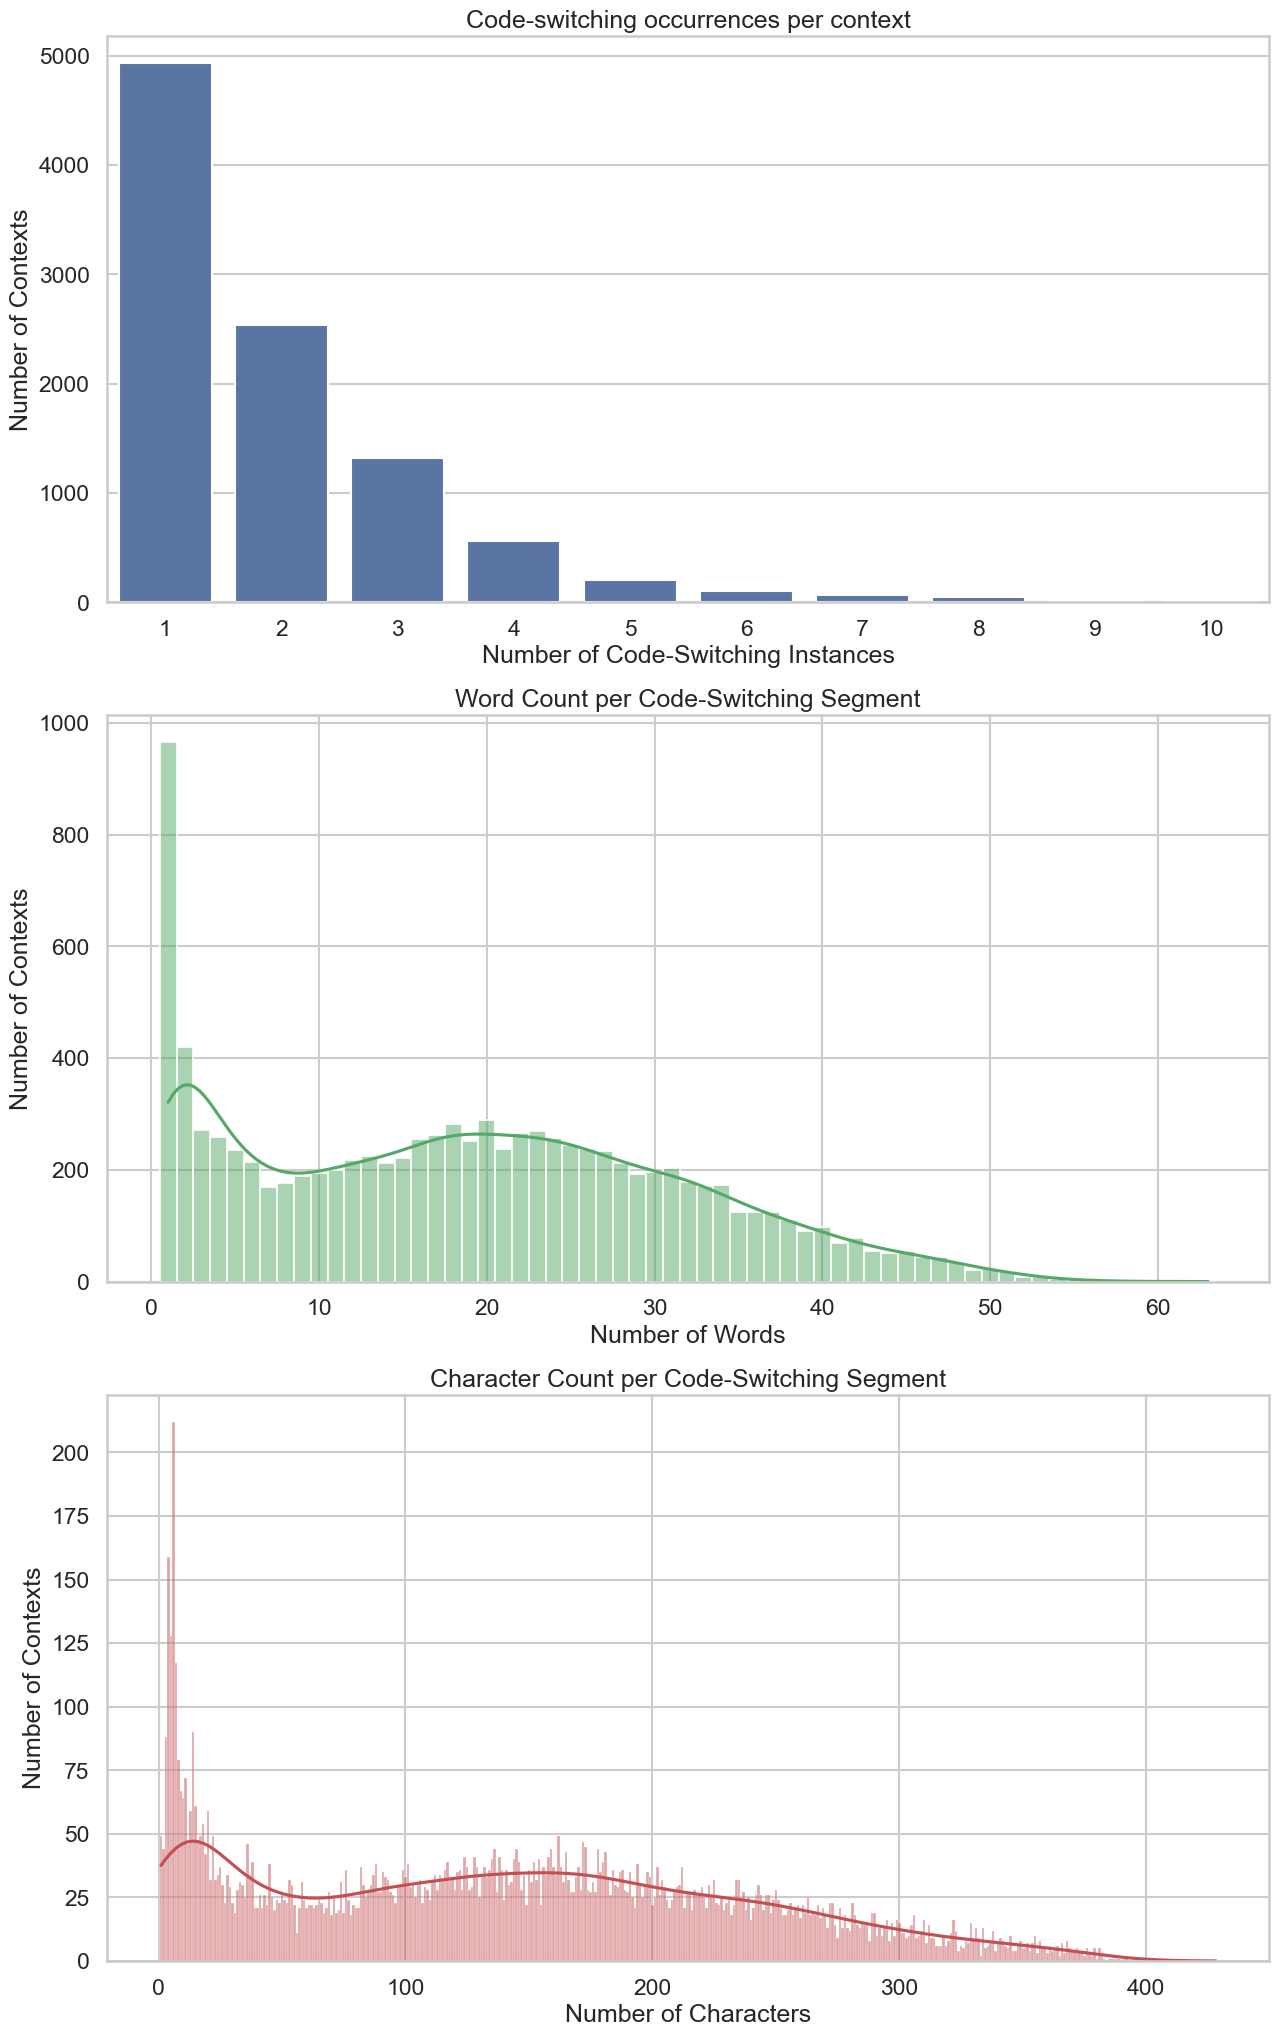

In [179]:
import matplotlib.pyplot as plt
import seaborn as sb

# Professional theme
sb.set_theme(style="whitegrid", context="talk", palette="colorblind")

fig, axes = plt.subplots(3, 1, figsize=(15, 25))
axes = axes.flatten()

# -------------------------
# 1. Code-switching counts
# -------------------------
CodeSwitch_Count_df = (
    df_exploded_segment.groupby("CodeSwitch_Count")
    .size()
    .reset_index(name="Num_Contexts")
)

sb.barplot(
    data=CodeSwitch_Count_df,
    x="CodeSwitch_Count",
    y="Num_Contexts",
    ax=axes[0],
    color="#4C72B0"  # muted blue (professional default tone)
)

axes[0].set_title("Code-switching occurrences per context")
axes[0].set_xlabel("Number of Code-Switching Instances")
axes[0].set_ylabel("Number of Contexts")

# -------------------------
# 2. Word count distribution
# -------------------------
sb.histplot(
    data=df_exploded_segment,
    x="Segment_Word_Count",
    kde=True,
    discrete=True,
    ax=axes[1],
    color="#55A868"  # muted green
)

axes[1].set_title("Word Count per Code-Switching Segment")
axes[1].set_xlabel("Number of Words")
axes[1].set_ylabel("Number of Contexts")

# -------------------------
# 3. Character count distribution
# -------------------------
sb.histplot(
    data=df_exploded_segment,
    x="Segment_Char_Count",
    kde=True,
    discrete=True,
    ax=axes[2],
    color="#C44E52"  # muted red
)

axes[2].set_title("Character Count per Code-Switching Segment")
axes[2].set_xlabel("Number of Characters")
axes[2].set_ylabel("Number of Contexts")


#### **Analyse des Stop-Words**

**Traitement :**

In [78]:
import nltk
from nltk.corpus import stopwords
nltk.download("stopwords")

arabic_stopwords = set(stopwords.words("arabic"))
len(arabic_stopwords)

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\exe\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


701

In [80]:
from bidi.algorithm import get_display
import arabic_reshaper

# Compter les Stopwords dans tout les paragraphes
def Analyse_Stopwords(column):
  sw_dict = {}
  for paragraph in column:
    tokens = paragraph.split()
    for word in tokens:
      if word in arabic_stopwords:
        if word in sw_dict:
          sw_dict[word] += 1
        else:
          sw_dict[word] = 1
  return sw_dict

# Convert to DataFrame
sw_results_dict = Analyse_Stopwords(context_df["first_paragraph"])
sw_results_df = pd.DataFrame(list(sw_results_dict.items()), columns=["Stopword", "Frequency"])

# Sort descending
sw_results_df = sw_results_df.sort_values(by="Frequency", ascending=False)

# Changer Textes arabes pour correcte affichage dans matplotlib
sw_results_df["Stopword"] = sw_results_df["Stopword"].apply(arabic_reshaper.reshape)
sw_results_df["Stopword"] = sw_results_df["Stopword"].apply(get_display)
sw_results_df


,Stopword,Frequency
4,ﻲﻓ,15262
0,ﻦﻣ,14958
3,ﻰﻠﻋ,8512
15,ﻦﻋ,3193
16,ﻲﺘﻟﺍ,2671
...,...,...
339,ﺎﺘﻠﻛ,1
340,ﻑﺎﻛ,1
341,ﻮﻤﺣ,1
342,ﺓﺮﻴﻟ,1


In [81]:
def Analyse_Stopwords_paragraph(paragraph):
  sw_count = 0
  tokens = paragraph.split()
  for word in tokens:
    if word in arabic_stopwords:
        sw_count += 1
  return sw_count

sw_count_df = context_df
sw_count_df["Stopword_Count"] = context_df["first_paragraph"].apply(Analyse_Stopwords_paragraph)
sw_count_df


,first_paragraph,nombre_mots,nombre_Caracteres,type,Stopword_Count
0,علمت “كود”، من مصادر مقربة من رئيس الحكومة ال...,37,216,arabic,6
5,temeknet fer9et echortet el9odaiya ettabi3a le...,34,248,arabizi,1
9,وأبرزت الصحف التركية أن مدة العقد قد تصل إل...,21,110,arabic,4
12,"9alat nazha elwafi, elwazira elmontadiba elmok...",36,274,arabizi,0
15,أحمد الطيب: علمت “كود” من مصادر خاصة، أن الم...,28,178,arabic,3
...,...,...,...,...,...
58830,قال وزير الفلاحة والصيد البحري والتنمية القروي...,29,185,arabic,1
58834,"3ilmet “koud” men masdar 7izbi, 2n el2amin el3...",24,182,arabizi,0
58837,أعلنت هيئة الإذاعة البريطانية عن وفاة الروا...,25,158,arabic,5
58842,أعلن المكتب الإقليمي للاتحاد الوطني للشغل بالم...,22,147,arabic,1


In [82]:
# Counts
stopwords_count = sw_results_df["Frequency"].sum()     # total stopwords
total_words_count = context_df["nombre_mots"].sum() # total words in corpus

# Values for the pie chart
values = [stopwords_count, total_words_count - stopwords_count]
labels = ["Stopwords", "Autres Mots"]


**Affichage Des Résultats :**

In [83]:
print("Nombre totale des Stopwords : ", sw_results_df["Frequency"].sum())
print("Nombre totale de mots : ", context_df["nombre_mots"].sum())

Nombre totale des Stopwords :  81708
Nombre totale de mots :  782752


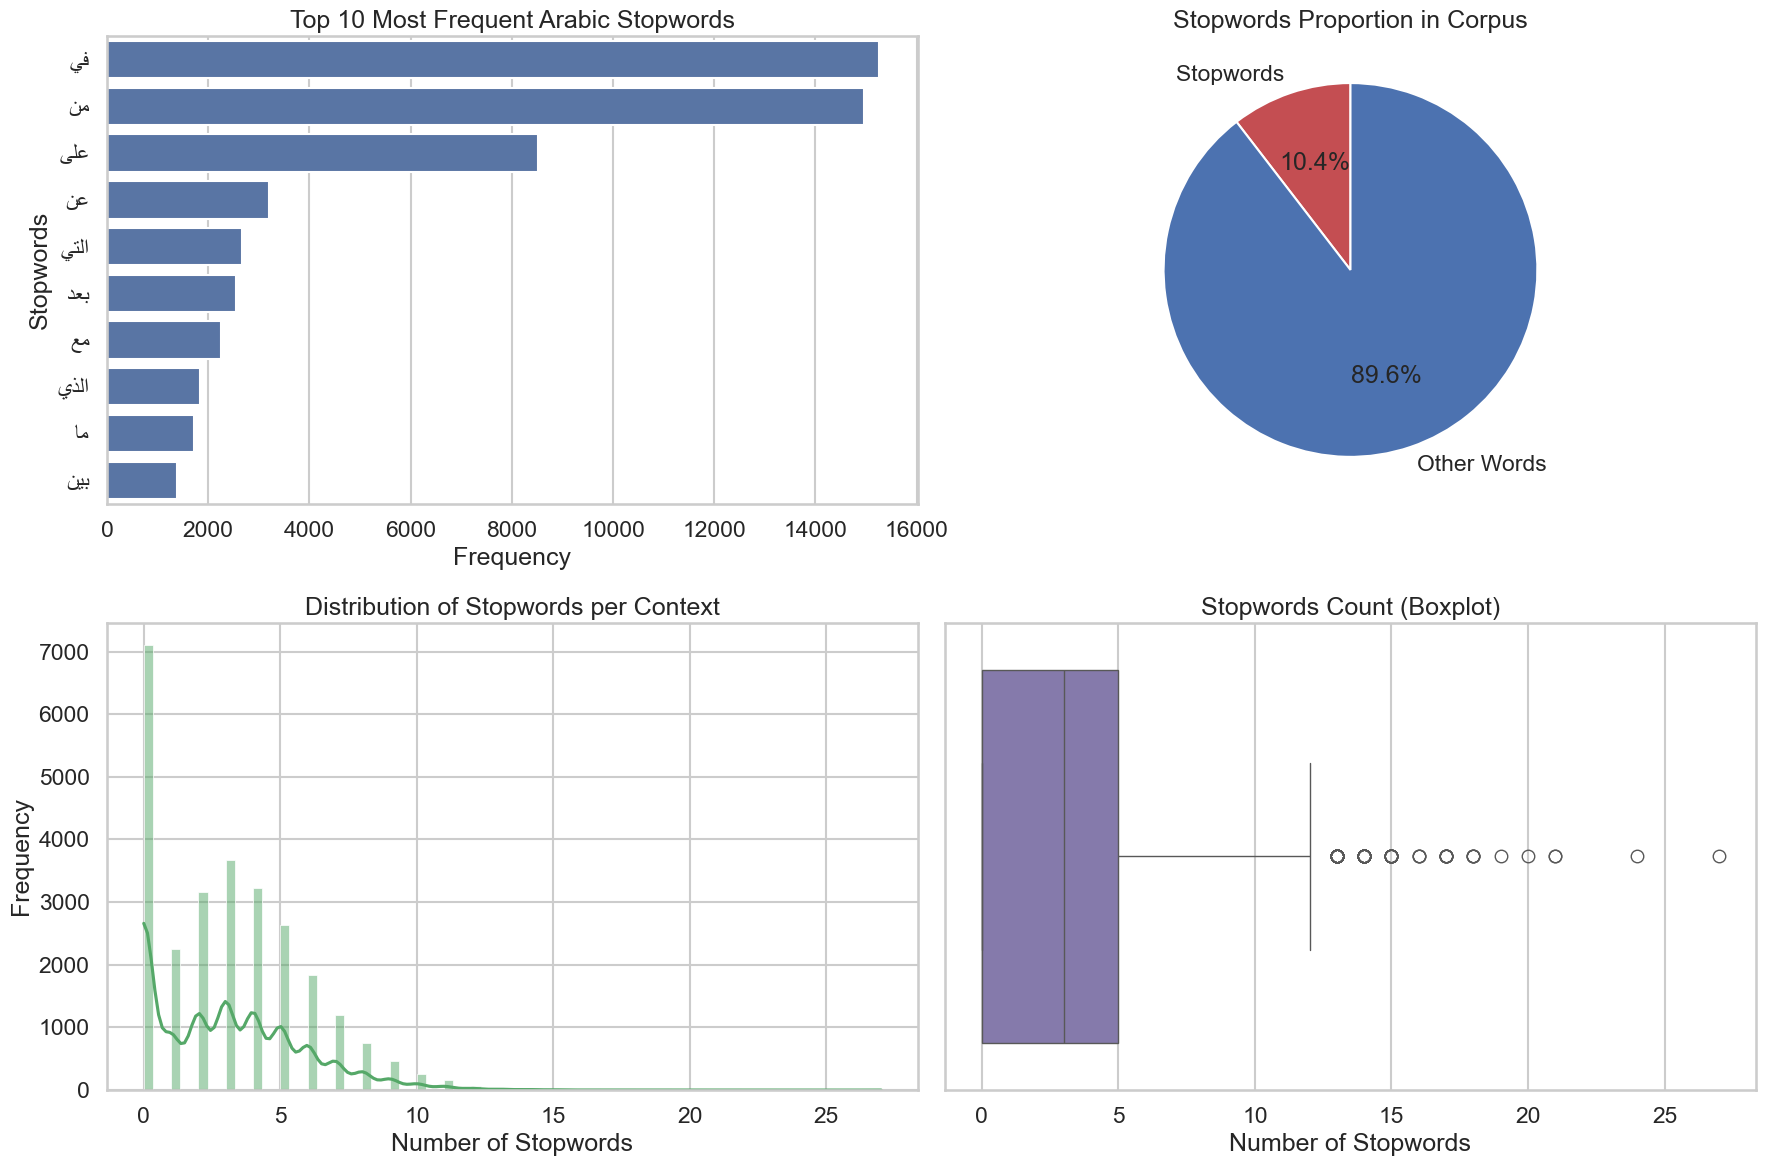

In [174]:
import matplotlib.pyplot as plt
import seaborn as sb

# Professional theme
sb.set_theme(style="whitegrid", context="talk", palette="colorblind")

fig, axes = plt.subplots(2, 2, figsize=(18, 12))
axes = axes.flatten()

# -------------------------
# 1. Top 10 stopwords
# -------------------------
sb.barplot(
    x="Frequency",
    y="Stopword",
    data=sw_results_df.head(10),
    ax=axes[0],
    color="#4C72B0"  # muted blue
)

axes[0].set_title("Top 10 Most Frequent Arabic Stopwords")
axes[0].set_xlabel("Frequency")
axes[0].set_ylabel("Stopwords")

# -------------------------
# 2. Stopwords proportion
# -------------------------
stopwords_count = sw_results_df["Frequency"].sum()
total_words_count = context_df["nombre_mots"].sum()

values = [stopwords_count, total_words_count - stopwords_count]
labels = ["Stopwords", "Other Words"]

axes[1].pie(
    values,
    labels=labels,
    autopct="%1.1f%%",
    startangle=90,
    colors=["#C44E52", "#4C72B0"]  # muted red & blue
)

axes[1].set_title("Stopwords Proportion in Corpus")

# -------------------------
# 3. Histogram
# -------------------------
sb.histplot(
    sw_count_df["Stopword_Count"],
    kde=True,
    ax=axes[2],
    color="#55A868"  # muted green
)

axes[2].set_title("Distribution of Stopwords per Context")
axes[2].set_xlabel("Number of Stopwords")
axes[2].set_ylabel("Frequency")

# -------------------------
# 4. Boxplot
# -------------------------
sb.boxplot(
    x=sw_count_df["Stopword_Count"],
    ax=axes[3],
    color="#8172B3"  # muted purple
)

axes[3].set_title("Stopwords Count (Boxplot)")
axes[3].set_xlabel("Number of Stopwords")

plt.tight_layout()
plt.show()

#### **Analyse des Question/Réponse Pairs**

In [133]:
qa_df = labelized_df.copy()
qa_df["type"] = qa_df["type"].replace("How many", "How Many")

In [134]:
print("Total QA pairs:", len(qa_df))

Total QA pairs: 93902


In [135]:
print("Total QA pairs:", len(qa_df))
print("Unique contexts:", qa_df['context'].nunique())
print("Avg QA per context:", len(qa_df) / qa_df['context'].nunique())

Total QA pairs: 93902
Unique contexts: 26863
Avg QA per context: 3.4955887279901723


In [136]:
print("Question Type Distribution:")
print(qa_df['type'].value_counts())

Question Type Distribution:
type
Who         28562
Where       19748
What        18989
When        12972
How Many     9752
Which        3851
Why            25
How             3
Name: count, dtype: int64


In [137]:
extractive_rate = qa_df.apply(lambda x: x['answer'] in x['context'], axis=1).mean()
print("Extractive Rate:", extractive_rate)

Extractive Rate: 0.9271048539967199


In [138]:
print("Average Question Length:", qa_df['question'].str.split().str.len().mean())
print("Average Answer Length:", qa_df['answer'].str.split().str.len().mean())
print("Average Context Length:", qa_df['context'].str.split().str.len().mean())

Average Question Length: 6.859534408212817
Average Answer Length: 2.4554216097633703
Average Context Length: 30.298800877510597


In [139]:
print("QA per Context Stats:")
print(qa_df.groupby('context').size().describe())

QA per Context Stats:
count    26863.000000
mean         3.495589
std          1.007108
min          1.000000
25%          3.000000
50%          3.000000
75%          4.000000
max          8.000000
dtype: float64


C:\Users\exe\AppData\Local\Temp\ipykernel_32320\1863641195.py:54: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[2, 1].set_xticklabels(counts['type'], rotation=45, ha='right')


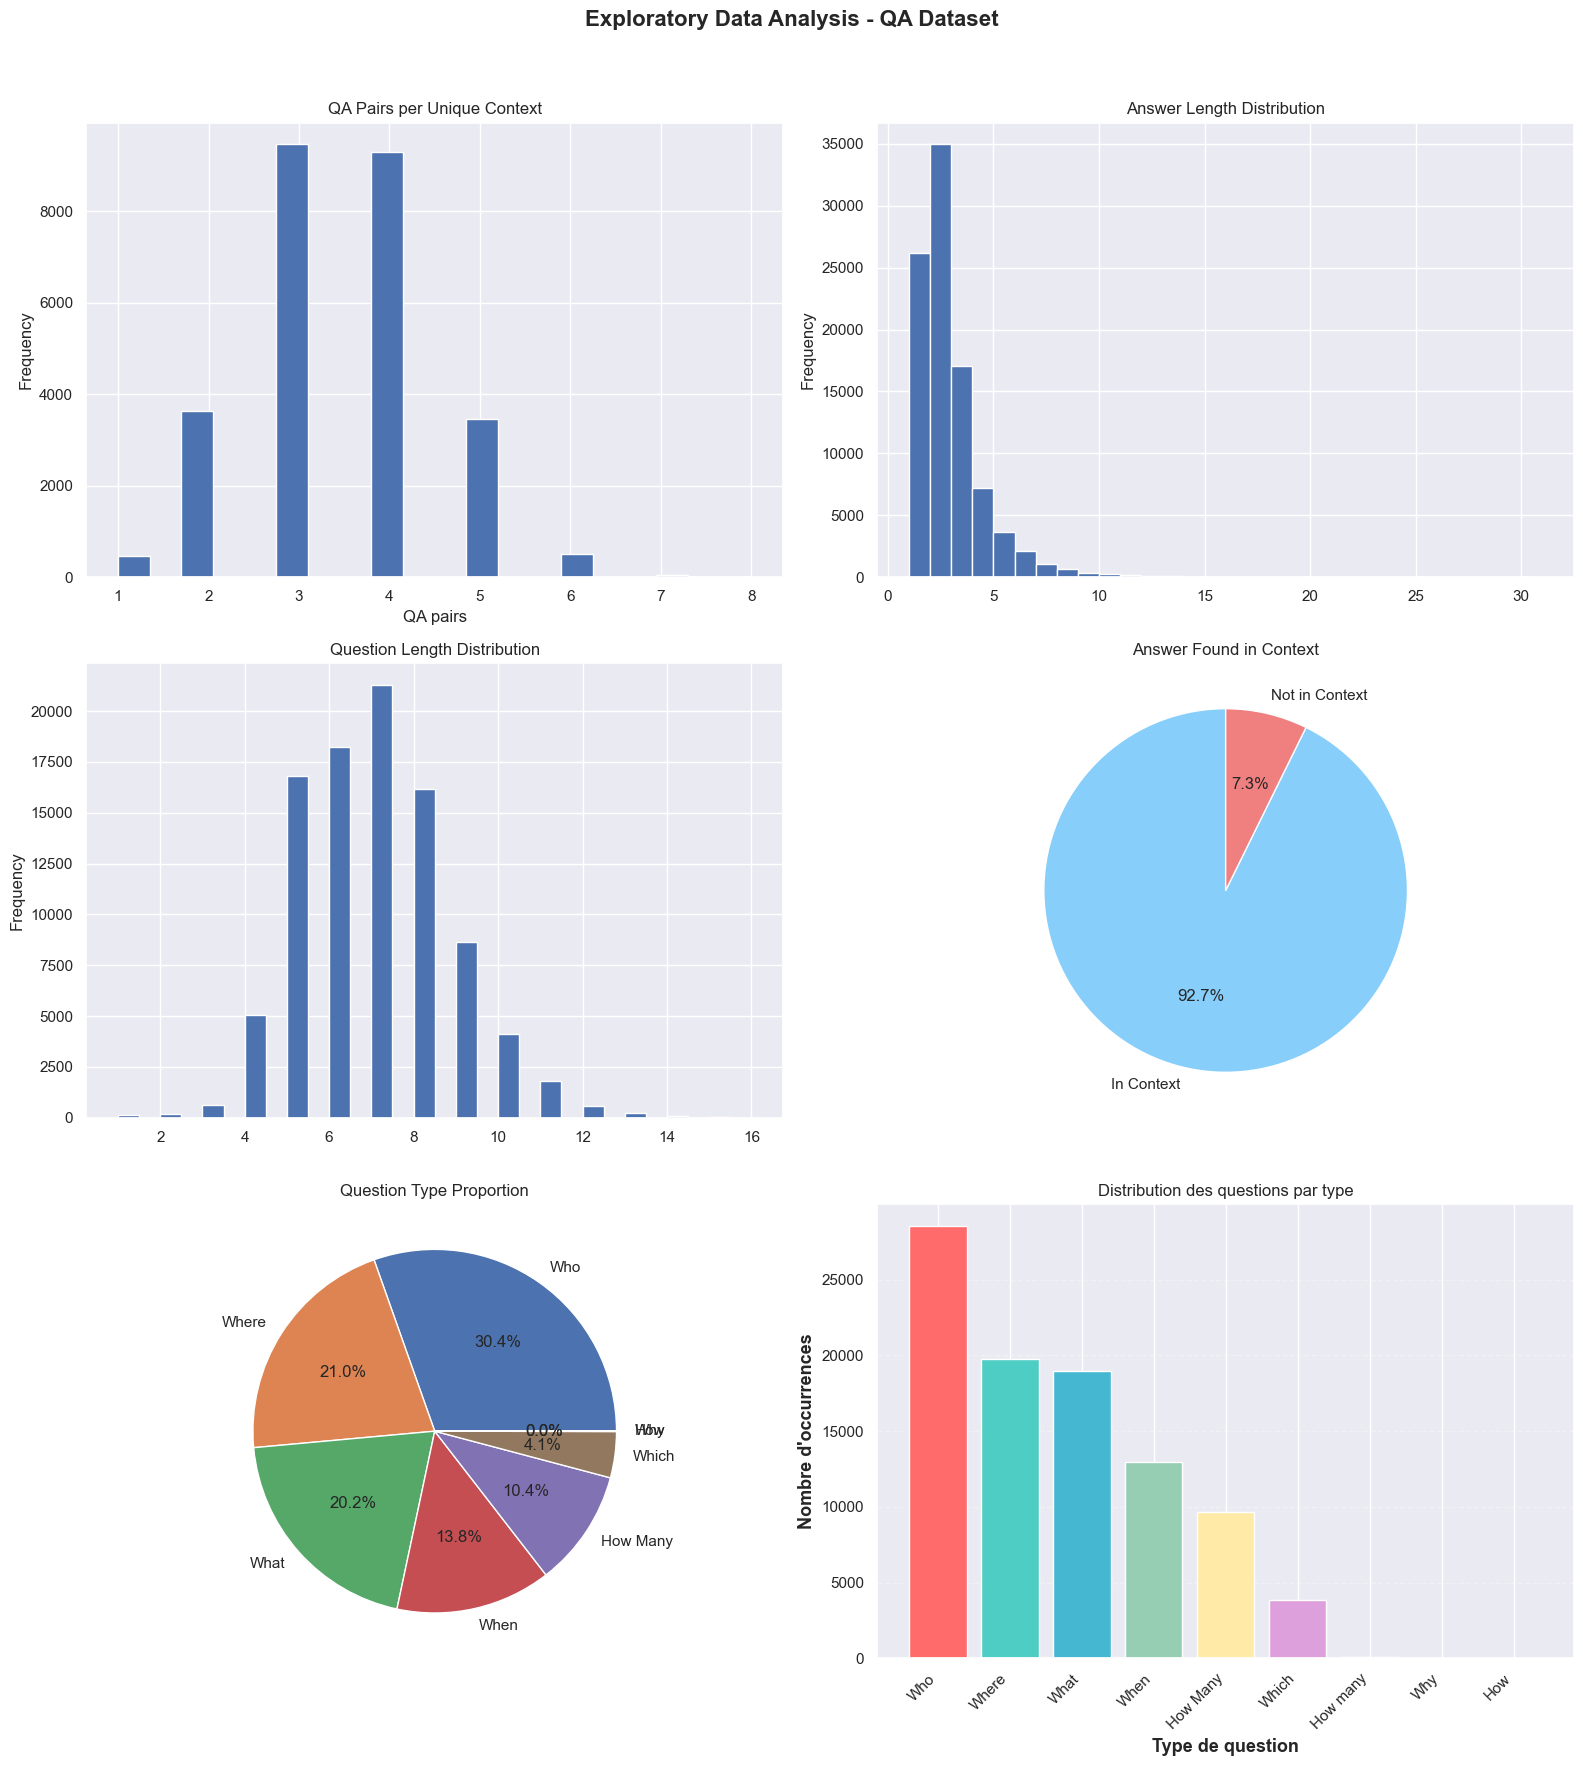

In [149]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 2, figsize=(16, 18))
fig.suptitle("Exploratory Data Analysis - QA Dataset", fontsize=16, fontweight='bold')

# 1. QA per Context
qa_df.groupby('context').size().plot(kind='hist', bins=20, ax=axes[0, 0])
axes[0, 0].set_title("QA Pairs per Unique Context")
axes[0, 0].set_xlabel("QA pairs")
axes[0, 0].set_ylabel("Frequency")

# 2. Answer Length
qa_df['answer'].str.split().str.len().plot(kind='hist', bins=30, ax=axes[0, 1])
axes[0, 1].set_title("Answer Length Distribution")

# 3. Question Length
qa_df['question'].str.split().str.len().plot(kind='hist', bins=30, ax=axes[1, 0])
axes[1, 0].set_title("Question Length Distribution")

# 4. Answer in Context (Pie)
counts_in = qa_df['in_context'].value_counts()
labels = ['In Context' if val else 'Not in Context' for val in counts_in.index]

axes[1, 1].pie(
    counts_in,
    labels=labels,
    autopct='%1.1f%%',
    startangle=90,
    colors=['lightskyblue', 'lightcoral']
)
axes[1, 1].set_title("Answer Found in Context")

# 5. Question Type (Pie)
qa_df['type'].value_counts().plot(kind='pie', autopct='%1.1f%%', ax=axes[2, 0])
axes[2, 0].set_title("Question Type Proportion")
axes[2, 0].set_ylabel("")

# 6. YOUR CUSTOM BAR CHART (added here)
counts = labelized_df.groupby("type")["context"].count().reset_index()
counts.columns = ["type", "count"]
counts = counts.sort_values("count", ascending=False)

colors = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#96CEB4', '#FFEAA7', '#DDA0DD']

axes[2, 1].bar(
    counts['type'],
    counts['count'],
    color=colors[:len(counts)]
)

axes[2, 1].set_title("Distribution des questions par type")
axes[2, 1].set_xlabel("Type de question", fontsize=13, fontweight='bold')
axes[2, 1].set_ylabel("Nombre d'occurrences", fontsize=13, fontweight='bold')
axes[2, 1].set_xticklabels(counts['type'], rotation=45, ha='right')
axes[2, 1].grid(axis='y', alpha=0.3, linestyle='--')
axes[2, 1].set_axisbelow(True)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()